# D55 Pruning Distillation Code

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

last modified date : 2026.11.05

# 프루닝과 지식 증류 구현 실습

## 오늘 확인할 문제

**가중치를 0으로 만들거나 층을 제거하거나 작은 모델을 학습시키면, 파일 크기·메모리·속도는 각각 어떻게 달라집니까?**

같은 업무 질문에서 프루닝 모델과 지식 증류 학생 모델의 파일 크기, GPU 메모리, 생성 속도, 정답 여부를 각각 측정해 사용할 경량화 방법을 고릅니다. D54에서 가중치 저장 비트 수를 줄인 데 이어 오늘은 가중치 일부를 0으로 만들거나 층을 제거하는 프루닝과 큰 모델의 답으로 작은 모델을 학습시키는 지식 증류를 비교합니다.

먼저 답과 이유를 두 문장으로 적습니다. 실습을 마치면 처음 판단을 자신의 결과로 고칩니다.

**학습목표**

- [목표 1] 희소화와 층 제거를 실행해 파일·메모리·속도 중 실제로 줄어든 것을 구분할 수 있다.
- [목표 2] 평가 질문과 분리한 교사 답을 검수하고 작은 학생 모델을 학습시킬 수 있다.
- [목표 3] 같은 하네스의 품질 변화와 자원 측정을 근거로 경량화 방법을 선택할 수 있다.

오늘은 Qwen2.5-1.5B-Instruct의 가중치를 두 방식으로 프루닝하고 Qwen2.5-0.5B-Instruct 학생 모델을 1.5B 교사 모델의 답으로 학습시킵니다. 프루닝 방식은 가중치 절반을 0으로 바꾸는 희소화(비구조적 50%와 2:4)와 층을 통째로 제거하는 층 프루닝입니다. 마지막 Step에서는 다음 두 날의 RunPod 실습에 쓸 모델 파일을 팀 네트워크 볼륨에 미리 받아 둡니다.

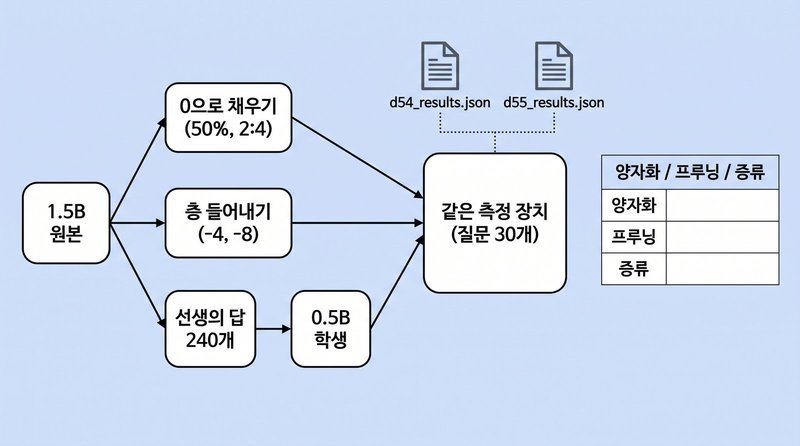

*프루닝한 모델과 증류한 모델을 양자화 노트와 같은 하네스로 측정해 한 표에 놓습니다.*

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 경량화 방법과 작은 행렬 실험 | 80분 | 이론 1\~3장, Step 0\~3 |
| 가중치·층 제거 후 자원 측정 | 100분 | 이론 4장, Step 4\~5 |
| 교사 모델의 답 검토와 학생 모델 학습 | 100분 | 이론 5장, Step 6 |
| 경량화 방법 선택과 D56 파일 준비 | 80분 | 이론 6장, Step 8\~9 |

이론 설명과 필수 실습을 합쳐 360분으로 계획했습니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함하면 하루 480분입니다. 표의 연결 위치를 따라 이론을 읽고 해당 실습을 이어서 진행합니다. 선택 실습과 접힌 심화 자료를 모두 추가하지 않습니다. 이 시간은 수업 계획이며 실제 진행 시간을 측정한 값은 아닙니다.

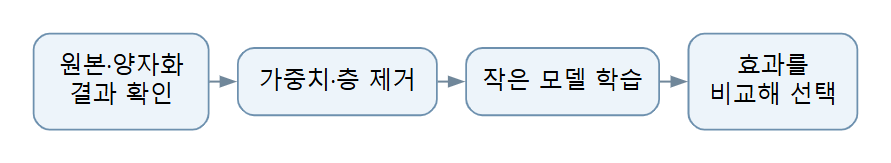

**실습 순서.** 원본·양자화 결과 확인 → 가중치·층 제거 → 작은 모델 학습 → 효과를 비교해 선택 순서로 진행합니다.

### 먼저 읽을 용어

| 용어 | 뜻과 실제로 하는 일 |
|---|---|
| 프루닝 |  가중치 일부나 층 등 모델 구조를 제거하는 방법 |
| 희소화 |  가중치 일부를 0으로 만드는 처리 |
| 지식 증류 |  교사 모델의 출력으로 학생 모델을 학습시키는 방법 |
| 보정 데이터 |  가중치를 제거하거나 양자화하기 전에 모델의 계산 특성을 살피는 입력 |

## 실행 환경

<div style="font-size: 18px; line-height: 1.6;">

| 항목 | 내용 |
|---|---|
| 런타임 | 코랩 Pro+ T4 (16GB). L4·A100도 됨 (Step 0\~7) |
| 로드하는 모델 | 1.5B 원본과 변형 넷(50%, 2:4, 층 -4, 층 -8), 0.5B 원본, 0.5B 증류본 (차례로 하나씩) |
| 다운로드하는 파일 | 1.5B 원본 3.1GB, 0.5B 원본 1GB 안팎 |
| 디스크 | 변형을 저장하는 데 15GB 안팎. Step 0에서 남은 디스크를 출력합니다 |
| 필요한 키 | 없음. 모델 제공자에게 별도 사용 승인을 신청하지 않고도 파일을 내려받을 수 있는 공개 저장소만 사용합니다 |
| RunPod (Step 8) | 팀 네트워크 볼륨 100GB와 그 데이터센터에서 가장 싼 GPU Pod. 금액은 RunPod 요금표에서 확인합니다 |

</div>

<div style="font-size: 18px; line-height: 1.6;">

| 오래 걸리는 셀 | 하는 일 | T4 기준 대략 (추정) |
|---|---|---|
| Step 0 설치 | 패키지 여섯 개 | 2\~4분 |
| Step 2 기준선 | 양자화 노트의 결과 파일이 없을 때 16비트와 NF4 측정 | 8\~12분 |
| Step 4 희소화 두 행 | 입력 크기 수집, 희소화, 저장, 측정 | 15\~25분 |
| Step 5 층 프루닝 두 행 | 층마다 변화 측정, 층 제거, 저장, 측정 | 12\~20분 |
| Step 6 증류 | 질문 240개에 1.5B가 답함(5\~10분), 0.5B 측정과 LoRA 학습 2에폭과 증류본 측정(10\~20분) | 15\~30분 |
| Step 7 트랙 1 | 회복 학습을 한 번 더 | 15\~40분 |
| Step 8 다운로드 | 32B AWQ 19.3GB와 7B 원본을 팀 볼륨에 받음 | 네트워크에 따라 다릅니다. 받는 동안 Step 9를 진행합니다 |

</div>

**로컬 작업** 표시가 붙은 곳은 사내 GPU 서버에서 달라지는 지점입니다. 코랩에서는 읽고 넘어가도 됩니다.

## Step 0. 환경 준비

In [ ]:
!pip install -q "transformers>=5.17,<6" "accelerate>=1.15,<2" "bitsandbytes>=0.50,<0.51" "datasets>=5.0,<6"
!pip install -q "trl>=1.13,<2" "peft>=0.21,<0.22"

# 설치가 끝나면 [런타임] - [세션 다시 시작]을 한 번 누르고 이 셀 아래부터 실행하세요

In [ ]:
import os, gc, json, math, re, time, random, shutil
from collections import Counter
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def pkgver(dist):
    try:
        return version(dist)
    except PackageNotFoundError:
        return "미설치"


print({d: pkgver(d) for d in ["torch", "transformers", "bitsandbytes", "datasets", "trl", "peft"]})

{'torch': '2.11.0+cu130', 'transformers': '5.22.0', 'bitsandbytes': '0.50.2', 'datasets': '5.1.0', 'trl': '1.17.1', 'peft': '0.21.2'}

In [ ]:
HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    prop = torch.cuda.get_device_properties(0)
    CAP = torch.cuda.get_device_capability(0)
    NATIVE_BF16 = CAP[0] >= 8
    print(f"GPU : {prop.name} / compute capability {CAP[0]}.{CAP[1]} / 메모리 {prop.total_memory / 1e9:.1f} GB")
else:
    CAP, NATIVE_BF16 = None, False
    print("GPU 런타임이 아닙니다. [런타임] - [런타임 유형 변경]에서 GPU를 고르고 다시 실행하세요.")
DTYPE16 = torch.float16  # AWQ와 같은 기준으로 비교합니다

# 경로와 모델 이름은 환경 변수에서 읽습니다(사내 서버에서는 내부 경로)
WORK = Path(os.environ.get("D55_WORK", "/content/d55"))
WORK.mkdir(parents=True, exist_ok=True)
STUDENT_ID = os.environ.get("D55_STUDENT_ID", "Qwen/Qwen2.5-0.5B-Instruct")
D54_CANDIDATES = [Path(os.environ.get("D55_D54_FILE", "/content/d54_results.json")), WORK / "d54_results.json"]
N_CALIB = int(os.environ.get("D55_N_CALIB", "64"))                 # 프루닝 보정 글 수 (이론 노트 2.2절)
DROP_LIST = [int(x) for x in os.environ.get("D55_DROP_LIST", "4,8").split(",")]   # 제거할 층 수
N_PER_TYPE = int(os.environ.get("D55_N_PER_TYPE", "60"))           # 증류 질문 수 (유형마다)

free_gb = shutil.disk_usage(WORK).free / 1e9
print(f"작업 폴더 {WORK} / 남은 디스크 {free_gb:.0f} GB (20GB보다 적으면 측정한 변형 폴더를 지우며 진행)")

GPU : Tesla T4 / compute capability 7.5 / 메모리 15.6 GB
작업 폴더 /content/d55 / 남은 디스크 253 GB (20GB보다 적으면 측정한 변형 폴더를 지우며 진행)

## 공통 준비 코드. 하네스 파일 다시 만들기

양자화 노트 코드가 만든 `bench_harness.py`가 작업 폴더에 없을 때 실행합니다. 양자화 노트의 `%%writefile` 셀 여섯 개와 같은 내용이고 빈칸은 정답으로 채워 두었습니다. 위에서부터 차례로 실행하면 현재 폴더(코랩은 `/content`)에 파일이 생깁니다. 그다음 본 실습 Step 1부터 다시 실행합니다.

**첫 셀부터 차례로 실행합니다.** 두 번째 셀부터는 `-a`로 뒤에 덧붙이므로 중간 셀만 다시 실행하면 같은 내용이 두 번 들어갑니다.

In [ ]:
%%writefile bench_harness.py
"""54일차 벤치마크 하네스. 55~57일차가 import 해서 씁니다"""
import gc, json, math, os, re, time
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

HAS_GPU = torch.cuda.is_available()
# Step 0 과 같은 규칙 : bf16 은 compute capability 8 이상
DTYPE16 = torch.float16  # 같은 fp16 기준선으로 정밀도 효과를 비교합니다

# 모델 이름은 환경 변수가 있으면 거기서 읽습니다. 서빙 프로젝트에서 들인 습관입니다
MODEL_ID = os.environ.get("D54_MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct")
# 측정할 때는 GPU 0번에 고정합니다. "auto" 로 두면 메모리가 모자랄 때 조용히 CPU 로 내려가
# 속도 측정값이 엉뚱해집니다(로컬 GPU 배포 노트 4.2절의 로드 방식)
DEVICE_MAP = {"": 0} if HAS_GPU else "cpu"

SYSTEM = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."

TEXT_KO = """한결물산 근무 규정 (실습용으로 지어낸 문서입니다)

제1조 (목적) 이 규정은 한결물산 임직원의 근무 시간, 재택근무, 휴가, 출장, 정보 보안에 관한 기준을 정한다.
제2조 (근무 시간) 기본 근무 시간은 오전 9시부터 오후 6시까지이며 점심시간은 낮 12시부터 1시까지 한 시간이다. 시차 출퇴근제를 신청한 직원은 오전 8시에서 10시 사이에 출근할 수 있다.
제3조 (재택근무) 재택근무는 주 2일까지 신청할 수 있다. 신청은 사용 전날 오후 3시까지 팀장에게 한다. 신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.
제4조 (연차 휴가) 1년 이상 근무한 직원에게는 연 15일의 연차를 준다. 연차는 반일 단위로 나누어 쓸 수 있다. 3일 이상 연속으로 쓰려면 2주 전까지 신청한다.
제5조 (출장비) 국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다. 식비는 하루 3만 원을 정액으로 지급한다. 출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.
제6조 (정보 보안) 회사 노트북은 자리를 비울 때 반드시 화면을 잠근다. 고객 정보가 담긴 파일은 외부 메일로 보내지 않는다. 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
제7조 (경조 휴가) 본인 결혼 시 5일, 자녀 결혼 시 1일의 경조 휴가를 준다. 부모가 사망한 경우에는 5일을 준다.
제8조 (교육 지원) 직무와 관련된 외부 교육비는 연 100만 원까지 지원한다. 교육을 마친 직원은 2주 안에 결과 보고서를 낸다.
제9조 (장비 대여) 업무용 모니터와 키보드는 총무팀에서 빌릴 수 있다. 빌린 장비는 퇴사 전에 반납한다.
제10조 (법인카드) 법인카드는 업무 목적에만 쓴다. 한 번에 50만 원을 넘는 결제는 재무팀의 사전 승인을 받는다.
제11조 (회의) 정기 회의는 매주 월요일 오전 10시에 연다. 회의록은 회의가 끝난 날 안에 공유한다.
제12조 (개정) 이 규정을 바꿀 때는 시행 2주 전까지 전 직원에게 알린다."""

TEXT_EN = """Hangyeol Trading Work Rules (a document made up for this exercise)

Article 1 (Purpose) These rules set the standards for working hours, remote work, leave, business trips, and information security for employees of Hangyeol Trading.
Article 2 (Working hours) Regular working hours are from 9 a.m. to 6 p.m., and the lunch break is one hour from noon to 1 p.m. Employees who have applied for flexible hours may start work between 8 a.m. and 10 a.m.
Article 3 (Remote work) Employees may apply for remote work up to two days a week. Applications are made to the team leader by 3 p.m. on the day before. New employees may apply for remote work only after three months from joining.
Article 4 (Annual leave) Employees who have worked for one year or more receive 15 days of annual leave a year. Annual leave may be divided into half-day units. To take three or more consecutive days, apply at least two weeks in advance.
Article 5 (Travel expenses) For domestic business trips, accommodation is paid at actual cost up to 100,000 won per night. Meals are paid at a flat rate of 30,000 won per day. Settlement is requested with receipts within five days after the trip ends.
Article 6 (Information security) Company laptops must always be screen-locked when the employee leaves the desk. Files containing customer information are not sent by external email. An employee who learns of a security incident reports it to the security team within one hour.
Article 7 (Family event leave) Employees receive five days of leave for their own wedding and one day for a child's wedding. Five days are given when a parent dies.
Article 8 (Training support) External training related to the job is supported up to 1,000,000 won a year. Employees who complete training submit a report within two weeks.
Article 9 (Equipment rental) Work monitors and keyboards can be borrowed from the general affairs team. Borrowed equipment is returned before leaving the company.
Article 10 (Corporate card) The corporate card is used only for business purposes. Any single payment over 500,000 won requires prior approval from the finance team.
Article 11 (Meetings) The regular meeting is held every Monday at 10 a.m. Minutes are shared on the same day the meeting ends.
Article 12 (Amendment) When these rules change, all employees are notified at least two weeks before they take effect."""

TEXTS = {"ko": TEXT_KO, "en": TEXT_EN}

Writing bench_harness.py

In [ ]:
%%writefile -a bench_harness.py


LABELS = ["인사", "보안", "재무", "총무"]


def q_rule(qid, rule, question, answer):
    return {"id": qid, "type": "지문", "kind": "num", "answer": answer,
            "q": f"다음 규정을 읽고 답하십시오.\n규정 : {rule}\n질문 : {question} 숫자만 답하십시오."}


def q_calc(qid, question, answer):
    return {"id": qid, "type": "계산", "kind": "num", "answer": answer,
            "q": f"{question} 숫자만 답하십시오."}


def q_label(qid, text, answer):
    return {"id": qid, "type": "분류", "kind": "label", "answer": answer,
            "q": f"다음 문의를 {', '.join(LABELS)} 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.\n문의 : {text}"}


def q_json(qid, sentence, dept, date):
    return {"id": qid, "type": "형식", "kind": "json", "answer": {"부서": dept, "날짜": date},
            "q": ("다음 문장에서 부서와 날짜를 뽑아 JSON 한 줄로만 답하십시오. "
                  "키는 \"부서\"와 \"날짜\"이고 날짜는 YYYY-MM-DD 형식으로 씁니다.\n"
                  f"문장 : {sentence}")}


QUESTIONS = [
    q_rule("A1", "재택근무는 주 2일까지 신청할 수 있다.", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2),
    q_rule("A2", "신청은 사용 전날 오후 3시까지 팀장에게 한다.", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3),
    q_rule("A3", "신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.", "신입 직원은 입사 후 몇 개월이 지나야 재택근무를 신청할 수 있습니까?", 3),
    q_rule("A4", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다.", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15),
    q_rule("A5", "3일 이상 연속으로 쓰려면 2주 전까지 신청한다.", "연차를 3일 이상 이어서 쓰려면 몇 주 전까지 신청해야 합니까?", 2),
    q_rule("A6", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다.", "국내 출장의 1박 숙박비는 최대 몇 만 원까지 받을 수 있습니까? 만 원 단위로", 10),
    q_rule("A7", "출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.", "출장비 정산은 출장을 마친 뒤 며칠 안에 신청해야 합니까?", 5),
    q_rule("A8", "보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1),
    q_calc("B1", "연차 15일 중 4.5일을 썼습니다. 남은 연차는 며칠입니까?", 10.5),
    q_calc("B2", "출장 식비는 하루 3만 원입니다. 4일 출장이면 식비는 모두 몇 만 원입니까? 만 원 단위로", 12),
    q_calc("B3", "숙박비 상한은 1박에 10만 원이고 실제 숙박비는 1박에 8만 원이었습니다. 3박을 했다면 받는 숙박비는 모두 몇 만 원입니까? 만 원 단위로", 24),
    q_calc("B4", "직원 48명 중 25%가 재택근무를 신청했습니다. 신청한 직원은 몇 명입니까?", 12),
    q_calc("B5", "예산 1,200만 원 중 3분의 1을 교육비로 씁니다. 교육비는 몇 만 원입니까? 만 원 단위로", 400),
    q_calc("B6", "오전 9시에 출근해 오후 6시에 퇴근하고 점심시간이 한 시간입니다. 점심시간을 뺀 근무 시간은 몇 시간입니까?", 8),
    q_calc("B7", "반일 연차를 3번, 하루짜리 연차를 2번 썼습니다. 모두 며칠을 썼습니까?", 3.5),
    q_calc("B8", "출장 3일 동안 식비는 하루 3만 원이고 숙박은 2박에 1박당 9만 원이었습니다. 식비와 숙박비를 합하면 모두 몇 만 원입니까? 만 원 단위로", 27),
    q_label("C1", "노트북에 모르는 프로그램이 깔려 있고 창이 계속 뜹니다.", "보안"),
    q_label("C2", "출장비 영수증을 잃어버렸는데 정산은 어떻게 하나요?", "재무"),
    q_label("C3", "육아휴직을 신청하려면 서류를 언제까지 내야 하나요?", "인사"),
    q_label("C4", "회의실 빔프로젝터가 켜지지 않습니다.", "총무"),
    q_label("C5", "고객 명단 파일을 협력사에 메일로 보내도 되나요?", "보안"),
    q_label("C6", "법인카드 한도를 올리고 싶습니다.", "재무"),
    q_label("C7", "신입 사원 교육 일정을 알고 싶습니다.", "인사"),
    q_json("D1", "인사팀은 2026년 3월 4일에 신입 교육을 엽니다.", "인사팀", "2026-03-04"),
    q_json("D2", "2026년 11월 20일에 보안팀이 모의 해킹 훈련을 합니다.", "보안팀", "2026-11-20"),
    q_json("D3", "재무팀의 결산 보고는 2027년 1월 8일입니다.", "재무팀", "2027-01-08"),
    q_json("D4", "총무팀은 2026년 12월 1일부터 사무실 이전을 시작합니다.", "총무팀", "2026-12-01"),
    q_json("D5", "2026년 10월 15일에 영업팀 워크숍이 있습니다.", "영업팀", "2026-10-15"),
    q_json("D6", "개발팀의 배포 일정은 2026년 9월 30일로 잡혔습니다.", "개발팀", "2026-09-30"),
    q_json("D7", "법무팀은 2027년 2월 3일까지 계약서 검토를 마칩니다.", "법무팀", "2027-02-03"),
]

Appending to bench_harness.py

In [ ]:
%%writefile -a bench_harness.py


def first_number(text):
    """답에서 처음 나오는 숫자 하나. 천 단위 쉼표는 지웁니다"""
    m = re.search(r"-?\d+(?:\.\d+)?", text.replace(",", ""))
    return float(m.group()) if m else None


def check_answer(ans, kind, expect):
    """채점기. 확인하지 못하면 불합격이 기본입니다"""
    if kind == "num":
        v = first_number(ans)
        return v is not None and abs(v - float(expect)) < 1e-6
    if kind == "label":
        hits = [lab for lab in LABELS if lab in ans]
        return hits == [expect]                 # 둘 이상 말하면 고른 것이 아닙니다
    if kind == "json":
        m = re.fullmatch(r"\s*(\{.*\})\s*", ans, re.S)
        if not m:
            return False
        try:
            obj = json.loads(m.group())
        except json.JSONDecodeError:
            return False
        return all(str(obj.get(k, "")).strip() == v for k, v in expect.items())
    return False

Appending to bench_harness.py

In [ ]:
%%writefile -a bench_harness.py


def make_bnb_config(precision):
    """정밀도 이름을 양자화 설정으로 바꿉니다. 인자는 기본값에 맡기지 않고 전부 적습니다"""
    if precision == "16bit":
        return None
    if precision == "int8":
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=6.0)
    if precision == "int8_t0":                    # 부록 실습 D : 이상치 분리를 끈 8비트
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=0.0)
    if precision == "nf4":
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                  bnb_4bit_compute_dtype=DTYPE16, bnb_4bit_use_double_quant=True)
    if precision == "default4":                   # Step 6 : 한 줄짜리 설정
        return BitsAndBytesConfig(load_in_4bit=True)
    raise ValueError(f"모르는 정밀도 : {precision}")


def vram_gb(peak=False):
    """GPU 메모리(GB). GPU 가 없으면 None 을 반환합니다"""
    if not HAS_GPU:
        return None
    fn = torch.cuda.max_memory_allocated if peak else torch.cuda.memory_allocated
    return fn() / 1e9


def load_model(model_id, precision, pass_dtype=True):
    """모델을 로드해 딕셔너리 하나에 담아 반환합니다. 실패하면 예외 대신 error 를 담아 반환합니다"""
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    kwargs = {"device_map": DEVICE_MAP}
    if pass_dtype:
        kwargs["dtype"] = DTYPE16                 # torch_dtype= 은 폐기되었습니다
    qc = make_bnb_config(precision)
    if qc is not None:
        kwargs["quantization_config"] = qc
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return {"error": "GPU 메모리 부족", "precision": precision}
    except Exception as e:
        return {"error": f"{type(e).__name__}: {str(e)[:160]}", "precision": precision}
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return {"model_id": model_id, "precision": precision, "tok": tok, "model": model,
            "load_sec": time.time() - t0, "weights_gb": vram_gb(),
            "footprint_gb": model.get_memory_footprint() / 1e9}


def unload(h):
    """모델을 언로드하고 메모리가 실제로 줄었는지 수치로 보여 줍니다(모델 선택 실습의 방식)"""
    before = vram_gb()
    h["tok"] = h["model"] = None
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        after = vram_gb()
        print(f"  [언로드] GPU 메모리 {before:.2f} -> {after:.2f} GB")
        if before > 0.1 and after > before * 0.3:
            print("  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요")


def describe_layers(model):
    """층마다 어떤 형식으로 로드되었는지 셉니다. Qwen2 계열의 층 이름을 씁니다"""
    kinds = Counter(type(m).__name__ for _, m in model.named_modules()
                    if isinstance(m, nn.Linear) or "Linear" in type(m).__name__)
    q = model.model.layers[0].self_attn.q_proj
    info = {"선형 층": dict(kinds),
            "출력 층": f"{type(model.lm_head).__name__} {model.lm_head.weight.dtype}",
            "임베딩": str(model.model.embed_tokens.weight.dtype),
            "출력 층과 임베딩 공유": bool(getattr(model.config, "tie_word_embeddings", False))}
    if hasattr(q, "compute_dtype"):
        info["4비트 계산 형식"] = str(q.compute_dtype)
        info["4비트 형식"] = getattr(q.weight, "quant_type", "-")
    return info

Appending to bench_harness.py

In [ ]:
%%writefile -a bench_harness.py


@torch.no_grad()
def perplexity_top1(h, text, window=512, stride=256):
    """글 한 편의 퍼플렉서티와 위치마다의 1순위 예측을 측정합니다.

    윈도우를 stride 만큼 밀며 새로 들어온 토큰만 채점합니다(허깅페이스 문서의 방식).
    윈도우 크기와 stride 를 바꾸면 값이 바뀌므로 정밀도끼리 비교할 때는 고정합니다(이론 노트 6.2절).
    반환값 : (퍼플렉서티, 1순위 예측 텐서, 채점한 토큰 수)
    """
    tok, model = h["tok"], h["model"]
    ids = tok(text, return_tensors="pt")["input_ids"].to(model.device)
    n = ids.shape[1]
    nll_sum, count, preds, prev_end = 0.0, 0, [], 0
    for begin in range(0, n, stride):
        end = min(begin + window, n)
        x = ids[:, begin:end]
        logits = model(x).logits.float()          # 확률 계산은 32비트로 합니다
        k = min(end - prev_end, x.shape[1] - 1)    # 이번 윈도우에서 새로 채점할 토큰 수
        if k <= 0:                                # 토큰이 하나뿐인 윈도우는 채점할 것이 없습니다
            prev_end = end
            continue
        lg = logits[:, :-1][:, -k:]               # 위치 t 의 출력이 토큰 t+1 을 맞힙니다
        tgt = x[:, 1:][:, -k:]
        nll_sum += F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tgt.reshape(-1),
                                   reduction="sum").item()
        count += tgt.numel()
        preds.append(lg.argmax(-1).flatten().cpu())
        prev_end = end
        if end == n:
            break
    return math.exp(nll_sum / count), torch.cat(preds), count


def chat_inputs(h, user_text):
    """시스템 프롬프트를 붙여 모델 입력을 만듭니다.

    transformers 5 의 apply_chat_template 은 return_tensors="pt" 일 때 텐서가 아니라
    input_ids 와 attention_mask 묶음을 반환합니다. 그래서 return_dict=True 를 적고 묶음으로 씁니다
    """
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]
    enc = h["tok"].apply_chat_template(msgs, add_generation_prompt=True,
                                       return_dict=True, return_tensors="pt")
    return {k: v.to(h["model"].device) for k, v in enc.items()}


@torch.no_grad()
def ask(h, user_text, max_new_tokens=64):
    """샘플링 없이 답 하나를 만듭니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    enc = chat_inputs(h, user_text)
    try:
        out = h["model"].generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=h["tok"].pad_token_id)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return "[생성 실패] GPU 메모리 부족"
    return h["tok"].decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


SPEED_PROMPTS = ["재택근무 규정을 다섯 문장으로 설명해 주세요.",
                 "출장비를 정산하는 순서를 단계별로 적어 주세요.",
                 "정보 보안 수칙 다섯 가지를 설명해 주세요."]


@torch.no_grad()
def tokens_per_sec(h, new_tokens=128):
    """사용자 한 명이 답을 받는 속도. 첫 호출은 준비 시간이 섞여 버리고 측정합니다"""
    ask(h, SPEED_PROMPTS[0], max_new_tokens=8)
    total, t0 = 0, time.time()
    for p in SPEED_PROMPTS:
        enc = chat_inputs(h, p)
        out = h["model"].generate(**enc, max_new_tokens=new_tokens, min_new_tokens=new_tokens,
                                  do_sample=False, pad_token_id=h["tok"].pad_token_id)
        total += out.shape[1] - enc["input_ids"].shape[1]
    if HAS_GPU:
        torch.cuda.synchronize()
    return total / (time.time() - t0)


def measure_all(h, questions=None, texts=None):
    """한 정밀도의 모든 지표를 측정합니다. 기준선과 비교하는 일은 표를 만들 때 합니다"""
    questions = QUESTIONS if questions is None else questions
    texts = TEXTS if texts is None else texts
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    r = {"precision": h["precision"], "model_id": h["model_id"], "load_sec": h["load_sec"], "actual_dtype": str(h["model"].dtype),
         "weights_gb": h["weights_gb"], "footprint_gb": h["footprint_gb"],
         "layers": describe_layers(h["model"]), "ppl": {}, "preds": {}, "answers": {}, "correct": {}}
    for lang, text in texts.items():
        ppl, preds, n = perplexity_top1(h, text)
        r["ppl"][lang], r["preds"][lang] = ppl, preds
    for q in questions:
        ans = ask(h, q["q"], max_new_tokens=96 if q["kind"] == "json" else 48)
        r["answers"][q["id"]] = ans
        r["correct"][q["id"]] = check_answer(ans, q["kind"], q["answer"])
    r["tps"] = tokens_per_sec(h)
    r["peak_gb"] = vram_gb(peak=True)
    return r

Appending to bench_harness.py

In [ ]:
%%writefile -a bench_harness.py


# 실습 : 16비트에서 맞힌 것이 틀린 수(맞→틀)와 틀린 것이 맞은 수(틀→맞)를 세는 함수를 완성하세요
# 입력은 둘 다 {질문 id: True/False} dict입니다

def count_flips(base_correct, other_correct):
    ### START CODE HERE ### (맞→틀, 틀→맞 질문 수 세기 2줄)
    # 1) base 에서 True 인데 other 에서 False 인 질문 수. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
    to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
    # 2) base 에서 False 인데 other 에서 True 인 질문 수
    to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
    ### END CODE HERE ###
    if to_wrong is None or to_right is None:
        return None
    return {"맞→틀": to_wrong, "틀→맞": to_right}


def top1_agreement(base_preds, other_preds):
    """같은 글, 같은 윈도우에서 다음 토큰 1순위가 기준선과 같은 비율"""
    if base_preds is None or other_preds is None or len(base_preds) != len(other_preds):
        return None
    return float((base_preds == other_preds).float().mean())


def fmt(v, spec):
    """값이 없으면(GPU 가 없을 때의 메모리 등) 같은 너비로 '-' 를 출력합니다"""
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)

def measurement_conditions(model_id, dtype16, questions=None):
    """기준선을 재사용할 수 있는 조건. 실측 결과와 조건을 따로 저장합니다."""
    import hashlib
    from importlib.metadata import version, PackageNotFoundError
    from pathlib import Path
    from huggingface_hub import snapshot_download
    questions = QUESTIONS if questions is None else questions
    def digest(value):
        return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    def installed(name):
        try: return version(name)
        except PackageNotFoundError: return None
    try:
        folder = Path(model_id) if Path(model_id).is_dir() else Path(snapshot_download(model_id, local_files_only=True))
        revision = folder.name if folder.parent.name == "snapshots" else digest(json.loads((folder / "config.json").read_text()))
    except (OSError, ValueError):
        revision = None
    return {"model": str(model_id), "revision": revision, "dtype16": str(dtype16),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "questions": len(questions), "questions_sha256": digest(questions),
            "generation_sha256": digest({"system": SYSTEM, "sample":False, "json_tokens":96, "other_tokens":48}),
            "harness_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
            "versions": {n:installed(n) for n in ["torch","transformers","accelerate","bitsandbytes"]}}


def matching_conditions(saved, current):
    return current.get("revision") is not None and all(saved.get(k) == v for k,v in current.items())

Appending to bench_harness.py

In [ ]:
# 다시 만든 파일의 채점기를 검산합니다(양자화 노트와 같은 검산, 1초). 어긋남이 0건이어야 합니다
from bench_harness import check_answer

SELF_TEST = [("2일입니다.", "num", 2, True), ("주 3일", "num", 2, False), ("보안 또는 총무", "label", "보안", False),
             ('{"부서": "인사팀", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, True)]
bad = [(a, k, e) for a, k, e, want in SELF_TEST if check_answer(a, k, e) != want]
print(f"채점기 검산 {len(SELF_TEST)}건 중 어긋남 {len(bad)}건", bad or "")

채점기 검산 4건 중 어긋남 0건

## Step 1. 벤치마크 하네스 재사용

양자화 노트 코드가 저장한 벤치마크 하네스 파일 `bench_harness.py`를 **그대로 불러와 씁니다.** 질문 30개와 채점기, 퍼플렉서티와 1순위 일치율, 초당 토큰과 메모리를 측정하는 `measure_all`, flip을 세는 `count_flips`입니다.

54일차가 만든 `bench_harness.py`를 작업 폴더(코랩은 드라이브 폴더, RunPod는 `/workspace`)에 둡니다. 없으면 앞의 공통 준비 코드를 먼저 실행합니다.

In [ ]:
import sys
from transformers import AutoModelForCausalLM, AutoTokenizer

# bench_harness.py 가 있는 폴더(드라이브라면 그 경로)
HARNESS_DIR = os.environ.get("BENCH_HARNESS_DIR", "/content")
if not (Path(HARNESS_DIR) / "bench_harness.py").exists():
    print(f"{HARNESS_DIR}/bench_harness.py 가 없습니다. 앞의 공통 준비 코드을 먼저 실행하세요")
sys.path.insert(0, HARNESS_DIR)
from bench_harness import (MODEL_ID, SYSTEM, TEXT_KO, TEXTS, LABELS, QUESTIONS, q_rule, q_calc, q_label, q_json,
                           check_answer, vram_gb, load_model, unload, perplexity_top1, chat_inputs, ask,
                           measure_all, count_flips, top1_agreement, fmt)

print(f"모델 : {MODEL_ID} / 질문 {len(QUESTIONS)}개 :", dict(Counter(q["type"] for q in QUESTIONS)))

모델 : Qwen/Qwen2.5-1.5B-Instruct / 질문 30개 : {'지문': 8, '계산': 8, '분류': 7, '형식': 7}

In [ ]:
from bench_harness import measurement_conditions, matching_conditions

하네스의 채점기와 측정 함수는 양자화 노트에서 검산을 마쳤습니다. 공통 준비 코드로 파일을 다시 만들었다면 그 끝의 검산 셀로 확인합니다.

In [ ]:
from huggingface_hub import snapshot_download
from transformers import GenerationConfig

# 하네스 바깥의 덧붙임 : 결과 저장, 디스크 크기, 기법 구분(branch), 층 수, 0의 비율
results = {}                                   # 행 이름 -> measure_all 결과 + 덧붙인 필드
RESULT_FILE = WORK / "d55_results.json"


def gb(v):
    return None if v is None else round(v, 2)


def weights_gb(path):
    folder = Path(path) if Path(path).exists() else Path(snapshot_download(str(path), local_files_only=True))
    return round(sum(f.stat().st_size for f in folder.rglob("*.safetensors")) / 1e9, 2)


def align_generation(h, ref_repo):
    """생성 설정을 같은 크기 원본의 설정으로 바꾸고 바뀐 값을 반환합니다"""
    ref, own = GenerationConfig.from_pretrained(ref_repo), h["model"].generation_config
    diff = {k: [getattr(own, k, None), getattr(ref, k, None)] for k in ("do_sample", "temperature", "top_p", "top_k")
            if getattr(own, k, None) != getattr(ref, k, None)}
    h["model"].generation_config = ref
    return diff


def zero_ratio(model):
    """층 안 선형 층의 가중치 가운데 0인 비율(임베딩과 출력 층 제외)"""
    ws = [m.weight for layer in model.model.layers for m in layer.modules() if type(m) is nn.Linear]
    total = sum(w.numel() for w in ws)
    return round(sum(int((w == 0).sum()) for w in ws) / total, 3) if total else None


def save_results():
    saved = {k: {kk: vv for kk, vv in r.items() if kk != "preds"} for k, r in results.items()}
    saved["_conditions"] = {"model": MODEL_ID, "student": STUDENT_ID, "questions": len(QUESTIONS),
                            "gpu": torch.cuda.get_device_name(0) if HAS_GPU else "CPU", "dtype16": str(DTYPE16),
                            "versions": {d: pkgver(d) for d in ["transformers", "trl", "peft"]}}
    saved["_conditions"]["training_versions"]={d:pkgver(d) for d in ["trl","peft"]}
    saved["_conditions"].update(measurement_conditions(MODEL_ID, DTYPE16))
    RESULT_FILE.write_text(json.dumps(saved, ensure_ascii=False, indent=1, default=str), encoding="utf-8")


def measure_file(name, path, precision, ref_repo, branch):
    """하네스로 측정하고 필드를 덧붙입니다. precision 은 16bit(원본·프루닝·증류본)나 nf4 입니다"""
    h = load_model(str(path), precision)
    if "error" in h:
        results[name] = {"precision": name, "branch": branch, "error": h["error"]}
        print(f"[{name}] 실패 : {h['error']}")
        return save_results()
    h["precision"] = name
    changed = align_generation(h, ref_repo)
    extra = {"branch": branch, "n_layers": h["model"].config.num_hidden_layers,
             "params_b": round(h["model"].num_parameters() / 1e9, 3), "zero_ratio": zero_ratio(h["model"])}
    r = measure_all(h)
    r.update({"disk_gb": weights_gb(path), "generation_changed": changed, "source": "D55", **extra})
    unload(h)
    results[name] = r
    save_results()
    print(f"[{name}] 정답 {sum(r['correct'].values())}/{len(QUESTIONS)} | 층 {r['n_layers']} | 0 비율 {r['zero_ratio']} "
          f"| 초당 {r['tps']:.1f} 토큰 | 디스크 {r['disk_gb']} GB")

## Step 2. 기준선과 양자화 노트의 결과 행

양자화 실습 노트 Step 5가 저장한 `d54_results.json`을 찾아 16비트 기준선과 8비트·NF4 행을 그대로 씁니다. 파일이 없거나 모델과 질문 수가 다르면 16비트와 NF4를 여기서 측정합니다.

오늘 비교하는 양자화 행은 이것뿐입니다. GPTQ·AWQ 행은 다음 노트에서 4비트 파일을 직접 만들어 더합니다.

In [ ]:
D54_FILE = next((p for p in D54_CANDIDATES if p.exists()), None)
if D54_FILE is not None and os.environ.get("D55_REMEASURE", "0") != "1":
    d54 = json.loads(D54_FILE.read_text(encoding="utf-8"))
    cond = d54.get("_conditions", {})
    if matching_conditions(cond, measurement_conditions(MODEL_ID, DTYPE16)):
        for p in ["16bit", "int8", "nf4"]:
            if p in d54 and "error" not in d54[p]:
                results[p] = dict(d54[p], source="양자화 노트", branch="기준" if p == "16bit" else "양자화")
    else:
        print("GPU·dtype·버전·질문·생성 조건이 달라 기존 기준선을 재사용하지 않습니다 :", cond)
print(f"{D54_FILE}에서 읽은 행 : {list(results)}")

if "16bit" not in results:          # 결과 파일이 없거나 D55_REMEASURE=1 이면 여기서 측정합니다
    measure_file("16bit", MODEL_ID, "16bit", ref_repo=MODEL_ID, branch="기준")
if not any(p in results for p in ["int8", "nf4"]):
    measure_file("nf4", MODEL_ID, "nf4", ref_repo=MODEL_ID, branch="양자화")
print("지금 있는 행 :", {k: v.get("source") for k, v in results.items()})

None에서 읽은 행 : []

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (3 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  [언로드] GPU 메모리 3.10 -> 0.01 GB
[16bit] 정답 19/30 | 층 28 | 0 비율 0.0 | 초당 11.3 토큰 | 디스크 3.09 GB

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 1.16 -> 0.01 GB
[nf4] 정답 13/30 | 층 28 | 0 비율 None | 초당 14.6 토큰 | 디스크 3.09 GB
지금 있는 행 : {'16bit': 'D55', 'nf4': 'D55'}

## Step 3. 작은 행렬의 프루닝

교재 : 5.7 자원 제약 장치용 모델 최적화

실제 모델을 프루닝하기 전에 작은 행렬로 원리를 봅니다.

In [ ]:
torch.manual_seed(0)
OUT_F, IN_F, N_TOK = 64, 256, 512
W = torch.randn(OUT_F, IN_F) * 0.02             # 가중치 : 출력 64개 × 입력 256개
X = torch.randn(N_TOK, IN_F)                     # 보정 글의 토큰 512개가 이 층에 넣는 입력
LOUD = torch.tensor([3, 70, 141, 200])           # 늘 큰 값이 들어오는 입력 채널 넷 (양자화 노트 3.2절의 이상치 차원)
X[:, LOUD] *= 20
X_NORM = X.norm(dim=0)                           # 입력 채널마다의 크기. 보정 데이터에서 모으는 통계입니다


def out_error(W_pruned):
    """프루닝한 뒤 출력의 상대 오차"""
    ref = X @ W.T
    return float((X @ W_pruned.T - ref).norm() / ref.norm())


def mask_unstructured(score, ratio):
    """행마다 점수가 낮은 ratio 만큼 제거. True가 남기는 위치"""
    k = int(score.shape[1] * ratio)
    drop = score.argsort(dim=1)[:, :k]
    keep = torch.ones_like(score, dtype=torch.bool)
    keep.scatter_(1, drop, False)
    return keep


def is_2of4(keep):
    """원소 4개 그룹마다 남긴 원소가 2개 이하인지"""
    groups = keep.reshape(keep.shape[0], -1, 4)
    return bool((groups.sum(-1) <= 2).all())


print(f"입력 채널 크기 : 보통 채널 평균 {X_NORM[~torch.isin(torch.arange(IN_F), LOUD)].mean():.1f}, 큰 채널 평균 {X_NORM[LOUD].mean():.1f}")

입력 채널 크기 : 보통 채널 평균 22.6, 큰 채널 평균 441.1

In [ ]:
# 실습 : 2:4 마스크를 완성하세요. 입력 쪽으로 원소 4개씩 묶고 그룹마다 점수가 높은 원소 2개만 남깁니다
def mask_2of4(score):
    out_f, in_f = score.shape
    groups = score.reshape(out_f, in_f // 4, 4)
    ### START CODE HERE ### (그룹 안의 순위를 구해 점수가 높은 원소 2개만 남기기 2줄)
    # 1) groups.argsort(dim=-1)를 한 번 더 argsort 하면 그룹 안의 순위(0이 가장 낮음)가 나옵니다
    rank = groups.argsort(dim=-1).argsort(dim=-1)   # 그룹 안의 순위. 0이 가장 낮고 3이 가장 높습니다
    # 2) 순위가 2 이상인 원소만 True 로 남깁니다. groups와 같은 모양이고 그룹마다 True 가 두 개입니다
    keep = rank >= 2                                # 높은 원소 2개만 남깁니다
    ### END CODE HERE ###
    if keep is None:
        return None
    return keep.reshape(out_f, in_f)


test = mask_2of4(torch.tensor([[0.1, 0.9, 0.5, 0.2, 3.0, 1.0, 2.0, 0.0]]))
if test is None:
    print("mask_2of4가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    print("테스트 :", test.int().tolist(), "/ 기대 [[0, 1, 1, 0, 1, 0, 1, 0]] / 2:4 패턴", is_2of4(test))

테스트 : [[0, 1, 1, 0, 1, 0, 1, 0]] / 기대 [[0, 1, 1, 0, 1, 0, 1, 0]] / 2:4 패턴 True

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
rank = groups.argsort(dim=-1).argsort(dim=-1)
keep = rank >= 2
```

비구조적 50%는 행 하나에서 아무 원소나 절반을 제거할 수 있지만 2:4는 **원소 4개마다 꼭 2개를 제거해야** 합니다. 중요한 원소 3개가 한 그룹에 몰려 있으면 하나를 잃습니다.

</details>

같은 50%를 제거하더라도 **무엇을 기준으로 제거하는지**에 따라 출력이 달라집니다.

In [ ]:
MAG = W.abs()                          # 크기 기준 : 가중치의 크기만 봅니다
WANDA = W.abs() * X_NORM               # Wanda : 가중치의 크기 × 그 채널에 들어오는 입력의 크기

cases = [("크기 기준 50%", mask_unstructured(MAG, 0.5)), ("Wanda 50%", mask_unstructured(WANDA, 0.5)),
         ("크기 기준 2:4", mask_2of4(MAG)), ("Wanda 2:4", mask_2of4(WANDA))]
print(f"{'방식':<12} {'0 비율':>6} {'출력 오차':>8} {'큰 입력 채널을 남긴 비율':>14}")
for name, keep in cases:
    if keep is None:
        print(f"{name:<12} 빈칸 : mask_2of4를 채우고 다시 실행하세요")
        continue
    loud = keep[:, LOUD].float().mean()
    print(f"{name:<12} {1 - keep.float().mean():>6.0%} {out_error(W * keep):>8.3f} {loud:>14.0%}")

방식             0 비율    출력 오차 큰 입력 채널을 남긴 비율
크기 기준 50%       50%    0.274            50%
Wanda 50%       50%    0.107            95%
크기 기준 2:4       50%    0.377            50%
Wanda 2:4       50%    0.146            97%

**읽는 순서**

1. **0 비율** : 네 행 모두 50%입니다. 제거한 개수는 같습니다  
2. **큰 입력 채널을 남긴 비율** : 크기 기준은 입력을 보지 않아서 큰 입력 채널의 가중치도 절반쯤 제거합니다. Wanda는 그 채널을 거의 다 남깁니다  
3. **출력 오차** : 큰 입력 채널의 가중치를 제거하면 출력이 크게 바뀝니다. 같은 기준이면 2:4가 비구조적 50%보다 오차가 큽니다. 제거할 위치를 고르는 자유가 줄었기 때문입니다

**0도 숫자입니다.** 보통 행렬은 0을 다른 값과 똑같이 16비트나 32비트에 담고 똑같이 곱합니다. 그래서 절반을 0으로 바꿔도 메모리는 그대로이고 곱셈 시간도 측정 변동 범위 안에서 같습니다(이론 노트 3.1절). 1.5B 전체로는 Step 4에서 확인합니다.

2048 × 2048 행렬로 직접 재 보는 셀과 L4·A100에서 2:4 희소 형식의 곱셈 시간을 재는 셀은 부록 실습 D에 있습니다.

## Step 4. 1.5B의 50%·2:4 희소화

교재 : 5.7 자원 제약 장치용 모델 최적화

Step 3의 Wanda 점수를 1.5B의 선형 층 196개에 씁니다. 보정 글을 모델에 입력해 층마다 입력 채널의 크기를 모으고 그 크기와 가중치의 크기를 곱한 점수가 낮은 절반을 0으로 바꿉니다.

보정 글은 평가 질문과 겹치면 안 됩니다.

In [ ]:
CALIB_SENTENCES = [
    "누리전자 사내 식당은 오전 11시 30분에 문을 열고 오후 1시 30분에 닫는다.",
    "식권은 사원증으로 결제하며 한 끼에 하나만 쓸 수 있다.",
    "본관 지하 주차장은 방문객 차량을 위해 두 개 층을 비워 둔다.",
    "택배는 1층 안내실에서 받고 이름과 내선 번호를 확인한 뒤 내준다.",
    "건강검진 결과는 개인 메일로만 보내고 부서장에게는 알리지 않는다.",
    "사내 메신저의 대화 기록은 1년이 지나면 자동으로 지워진다.",
    "소방 훈련 때에는 엘리베이터를 쓰지 않고 비상계단으로 내려간다.",
    "출입증은 다른 사람에게 빌려주지 않고 잃어버리면 안내실에 알린다.",
    "사무실 온도는 여름에 26도, 겨울에 20도로 맞춘다.",
    "신규 입사자의 자리는 입사 전날까지 총무 담당자가 준비한다.",
]
random.seed(56)
CALIB_TEXTS = [" ".join(random.sample(CALIB_SENTENCES, 5)) for _ in range(N_CALIB)]


def grams(texts, n=12):
    return {t[i:i + n] for t in texts for i in range(len(t) - n + 1)}


def leak_hits(texts, refs, n=12):
    """refs와 12자 넘게 겹치는 조각의 수. 0이어야 합니다"""
    ref_grams = grams(refs, n)
    return sum(1 for t in texts for i in range(len(t) - n + 1) if t[i:i + n] in ref_grams)


EVAL_TEXTS = [TEXT_KO] + [q["q"] for q in QUESTIONS]
print(f"보정 글 {len(CALIB_TEXTS)}개, 평균 {np.mean([len(t) for t in CALIB_TEXTS]):.0f}자 / "
      f"평가 질문·규정 글과 겹친 조각 {leak_hits(CALIB_TEXTS, EVAL_TEXTS)}개")

보정 글 64개, 평균 179자 / 평가 질문·규정 글과 겹친 조각 0개

In [ ]:
def decoder_linears(model):
    """층 안의 선형 층(임베딩과 lm_head 는 프루닝하지 않음)"""
    return [(n, m) for n, m in model.model.layers.named_modules() if type(m) is nn.Linear]


@torch.no_grad()
def collect_input_norms(h, texts, max_tokens=256):
    """선형 층마다 입력 채널의 크기(노름). Wanda가 쓰는 통계입니다"""
    sq, hooks = {}, []
    for name, m in decoder_linears(h["model"]):
        sq[name] = torch.zeros(m.in_features, device=m.weight.device, dtype=torch.float32)

        def hook(mod, args, out, name=name):
            x = args[0].reshape(-1, args[0].shape[-1]).float()
            sq[name] += (x * x).sum(0)
        hooks.append(m.register_forward_hook(hook))
    try:
        for t in texts:
            enc = h["tok"](t, return_tensors="pt", truncation=True, max_length=max_tokens)
            h["model"](enc["input_ids"].to(h["model"].device))
    finally:
        for hk in hooks:                          # 훅을 남기면 뒤의 모든 계산이 느려집니다
            hk.remove()
    return {k: v.sqrt() for k, v in sq.items()}


@torch.no_grad()
def prune_wanda(h, norms, pattern):
    """Wanda 점수(가중치 크기 × 입력 크기)가 낮은 가중치를 0으로 바꿉니다. pattern은 비율(0.5 등)이나 "2:4".
    원래 방법은 층을 차례로 프루닝하지만 여기서는 원본의 입력으로 한 번에 프루닝합니다"""
    for name, m in decoder_linears(h["model"]):
        score = m.weight.abs().float() * norms[name][None, :]
        keep = mask_2of4(score) if pattern == "2:4" else mask_unstructured(score, pattern)
        m.weight.mul_(keep.to(m.weight.dtype))

In [ ]:
PRUNE_DIRS = {}
patterns = [0.5]
if mask_2of4(torch.ones(1, 4)) is None:
    print("Step 3의 mask_2of4가 비어 있어 2:4 행은 건너뜁니다")
else:
    patterns.append("2:4")

for pattern in patterns:
    name = "wanda 2:4" if pattern == "2:4" else f"wanda {pattern:.0%}"
    out = WORK / ("1.5b-wanda-2of4" if pattern == "2:4" else f"1.5b-wanda-{int(pattern * 100)}pct")
    t0 = time.time()
    h = load_model(MODEL_ID, "16bit")
    if "error" in h:
        print(f"[{name}] 로드 실패 : {h['error']}")
        break
    norms = collect_input_norms(h, CALIB_TEXTS)
    prune_wanda(h, norms, pattern)
    ok24 = all(is_2of4(m.weight != 0) for _, m in decoder_linears(h["model"]))
    print(f"[{name}] 희소화 {time.time() - t0:.0f}초 | 0 비율 {zero_ratio(h['model'])} | 모든 층이 2:4 패턴 {ok24}")
    h["model"].save_pretrained(out)
    h["tok"].save_pretrained(out)
    unload(h)
    PRUNE_DIRS[name] = out
    measure_file(name, out, "16bit", ref_repo=MODEL_ID, branch="프루닝")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[wanda 50%] 희소화 10초 | 0 비율 0.5 | 모든 층이 2:4 패턴 False

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.10 -> 0.01 GB

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.10 -> 0.01 GB
[wanda 50%] 정답 11/30 | 층 28 | 0 비율 0.5 | 초당 23.5 토큰 | 디스크 3.09 GB

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.10 -> 0.01 GB

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.10 -> 0.01 GB
[wanda 2:4] 정답 2/30 | 층 28 | 0 비율 0.5 | 초당 23.0 토큰 | 디스크 3.09 GB

**눈여겨볼 곳**

- **디스크와 메모리** : 둘 다 원본과 같은 3.1GB입니다. 0을 보통 행렬에 담아 저장했기 때문입니다(Step 3)  
- **초당 토큰** : 원본과 측정 변동 범위 안에서 같아야 합니다. T4에는 0을 건너뛰는 장치가 없습니다

## Step 5. 층 프루닝

교재 : 5.7 자원 제약 장치용 모델 최적화

이번에는 가중치를 0으로 바꾸지 않고 **층을 통째로 제거합니다.** 행렬이 사라지므로 메모리와 디스크가 실제로 줄고 GPU 세대와 상관없이 빨라집니다.

어느 층을 제거할지는 층마다 **들어온 값과 나간 값이 얼마나 다른지**로 정합니다.

In [ ]:
@torch.no_grad()
def layer_change(h, texts, max_tokens=256):
    """층마다 들어온 값과 나간 값의 차이(1 - 코사인 유사도)의 토큰 평균"""
    layers = h["model"].model.layers
    sums, count, hooks = [0.0] * len(layers), 0, []
    for i, layer in enumerate(layers):
        def hook(mod, args, kwargs, out, i=i):
            x = args[0] if args else kwargs["hidden_states"]
            y = out[0] if isinstance(out, tuple) else out
            cos = F.cosine_similarity(x.float(), y.float(), dim=-1)      # 토큰마다 하나
            sums[i] += float((1 - cos).sum())
        hooks.append(layer.register_forward_hook(hook, with_kwargs=True))
    try:
        for t in texts:
            ids = h["tok"](t, return_tensors="pt", truncation=True, max_length=max_tokens)["input_ids"]
            h["model"](ids.to(h["model"].device))
            count += ids.shape[1]
    finally:
        for hk in hooks:
            hk.remove()
    return [s / count for s in sums]


h = load_model(MODEL_ID, "16bit")
CHANGE = layer_change(h, CALIB_TEXTS[:16]) if "error" not in h else None
if CHANGE is None:
    print("로드 실패 :", h["error"])
else:
    unload(h)
    top = max(CHANGE)
    for i, c in enumerate(CHANGE):
        print(f"층 {i:>2}  {c:.3f}  " + "#" * max(1, int(40 * c / top)))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.10 -> 0.01 GB
층  0  0.948  ########################################
층  1  0.238  ##########
층  2  0.181  #######
층  3  0.146  ######
층  4  0.112  ####
층  5  0.095  ####
층  6  0.098  ####
층  7  0.094  ###
층  8  0.075  ###
층  9  0.060  ##
층 10  0.060  ##
층 11  0.054  ##
층 12  0.040  #
층 13  0.044  #
층 14  0.035  #
층 15  0.033  #
층 16  0.035  #
층 17  0.052  ##
층 18  0.051  ##
층 19  0.074  ###
층 20  0.056  ##
층 21  0.098  ####
층 22  0.083  ###
층 23  0.098  ####
층 24  0.061  ##
층 25  0.060  ##
층 26  0.053  ##
층 27  0.384  ################

**읽는 법** : 막대가 짧은 층이 들어온 값을 적게 바꾼 층입니다. 공개된 측정들은 대개 첫 층과 마지막 층이 크게 바꾸고 마지막 층에 가까운 깊은 층들이 적게 바꾼다고 보고합니다. 여러분의 막대도 그런 모양인지 봅니다.

In [ ]:
# 실습 : 변화가 작은 층 n개를 고르세요. 첫 층과 마지막 층은 후보에서 뺍니다(이론 노트 4.1절)
def pick_layers_to_drop(change, n):
    candidates = list(range(1, len(change) - 1))
    ### START CODE HERE ### (변화가 작은 후보 n개를 골라 층 번호 순서로 정렬하기 1줄)
    # 1) candidates를 change가 작은 순서로 정렬해 앞에서 n개를 고르고 작은 번호부터 다시 정렬합니다
    picked = sorted(sorted(candidates, key=lambda i: change[i])[:n])
    ### END CODE HERE ###
    return picked


if CHANGE is not None:
    for n in DROP_LIST:
        picked = pick_layers_to_drop(CHANGE, n)
        if picked is None:
            print("pick_layers_to_drop이 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
            break
        print(f"{n}개 : {picked}")

4개 : [12, 14, 15, 16]
8개 : [12, 13, 14, 15, 16, 17, 18, 26]

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
picked = sorted(sorted(candidates, key=lambda i: change[i])[:n])
```

</details>

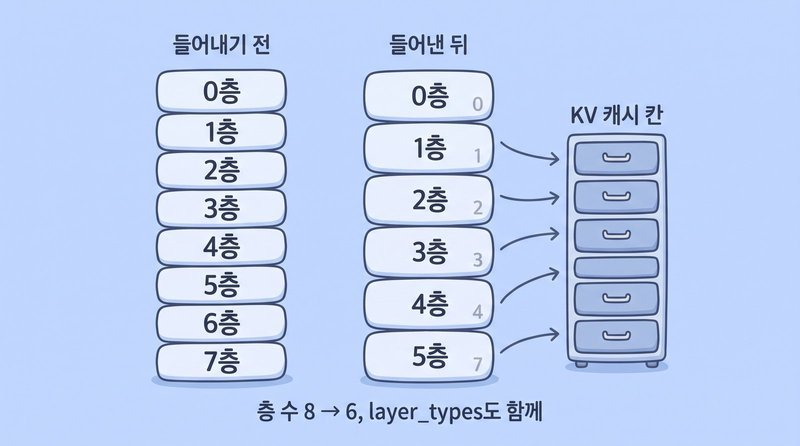

*층을 제거한 뒤에는 남은 층의 번호와 설정의 층 수를 함께 맞춰야 답을 쓰다가 멈추지 않습니다.*

In [ ]:
def drop_layers(model, drop):
    """층을 제거하고 남은 층의 번호와 설정을 맞춥니다"""
    keep = [i for i in range(len(model.model.layers)) if i not in set(drop)]
    model.model.layers = nn.ModuleList([model.model.layers[i] for i in keep])
    for new_i, layer in enumerate(model.model.layers):
        layer.self_attn.layer_idx = new_i         # KV 캐시에서 이 층이 쓰는 슬롯 번호입니다
    model.config.num_hidden_layers = len(keep)
    if getattr(model.config, "layer_types", None):
        model.config.layer_types = [model.config.layer_types[i] for i in keep]
    return keep


DROP_DIRS = {}
for n in DROP_LIST:
    drop = pick_layers_to_drop(CHANGE, n) if CHANGE is not None else None
    if drop is None:
        print("제거할 층을 정하지 못했습니다. 층 변화 셀과 실습 셀을 먼저 실행하세요")
        break
    name, out = f"층 -{n}", WORK / f"1.5b-drop{n}"
    h = load_model(MODEL_ID, "16bit")
    if "error" in h:
        print(f"[{name}] 로드 실패 : {h['error']}")
        break
    drop_layers(h["model"], drop)
    probe = ask(h, QUESTIONS[0]["q"])           # 층을 제거한 채로 답을 쓰는지 바로 확인합니다
    h["model"].save_pretrained(out)
    h["tok"].save_pretrained(out)
    print(f"[{name}] 제거한 층 {drop} | 매개변수 {h['model'].num_parameters() / 1e9:.3f}B | 테스트 답 {probe[:40]!r}")
    unload(h)
    DROP_DIRS[name] = out
    measure_file(name, out, "16bit", ref_repo=MODEL_ID, branch="프루닝")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[층 -4] 제거한 층 [12, 14, 15, 16] | 매개변수 1.357B | 테스트 답 '1일'
  [언로드] GPU 메모리 2.73 -> 0.01 GB

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  [언로드] GPU 메모리 2.73 -> 0.01 GB
[층 -4] 정답 1/30 | 층 24 | 0 비율 0.0 | 초당 26.1 토큰 | 디스크 2.71 GB

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[층 -8] 제거한 층 [12, 13, 14, 15, 16, 17, 18, 26] | 매개변수 1.169B | 테스트 답 '대로 해요, "재택근무를 하겠다" 떳_outer loop를 진행하면 됐습'
  [언로드] GPU 메모리 2.35 -> 0.01 GB

Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

  [언로드] GPU 메모리 2.35 -> 0.01 GB
[층 -8] 정답 0/30 | 층 20 | 0 비율 0.0 | 초당 30.9 토큰 | 디스크 2.34 GB

**눈여겨볼 곳**

- **디스크, 메모리, 초당 토큰** : 가중치를 0으로 바꾼 Step 4의 행과 달리 셋이 함께 움직입니다  
- **테스트 답** : 층을 제거한 직후에도 답이 나와야 합니다. 층 번호를 맞추지 않으면 이 줄에서 KV 캐시 오류가 납니다

## Step 6. 교사 모델의 답과 학생 모델 학습

교재 : 4.3.7 데이터 품질, 4.5.4 지시 파인 튜닝 데이터셋 자동 생성, 5.5.5 파라미터 효율적 파인 튜닝, 5.7 자원 제약 장치용 모델 최적화

여기서부터 증류입니다. 1.5B 원본이 교사 모델이고 0.5B가 학생 모델입니다. 학생 모델이 학습할 답은 **교사 모델이 쓴 답**이고 이 방식을 시퀀스 증류라고 합니다(이론 노트 5.3절). 증류 질문 만들기, 교사 모델의 답 생성과 필터, 학생 모델 학습, 오늘의 표의 순서로 진행합니다.

In [ ]:
rng = random.Random(56)

RULES = [  # (규정 문장, 질문, 고를 수 있는 숫자). 모두 실습용으로 지어낸 규정입니다
    ("사내 주차권은 한 사람에게 한 달 {n}장을 준다.", "사내 주차권은 한 사람이 한 달에 몇 장 받습니까?", [2, 3, 4, 5, 6, 8]),
    ("건강검진은 {n}년에 한 번 받는다.", "건강검진은 몇 년에 한 번 받습니까?", [1, 2, 3]),
    ("동호회 활동비는 1인당 한 달 {n}만 원을 지원한다.", "동호회 활동비는 1인당 한 달에 얼마입니까? 만 원 단위의 숫자로", [2, 3, 4, 5, 6]),
    ("야근 식대는 오후 {n}시가 넘어 퇴근하면 준다.", "야근 식대는 오후 몇 시가 넘어 퇴근해야 받습니까?", [7, 8, 9, 10]),
    ("계약 문서는 {n}년 동안 보관한다.", "계약 문서는 몇 년 동안 보관합니까?", [3, 5, 7, 10]),
    ("큰 회의실은 한 번에 {n}시간까지만 예약한다.", "큰 회의실은 한 번에 최대 몇 시간 동안 빌릴 수 있습니까?", [2, 3, 4]),
    ("명함은 {n}장 묶음으로 주문한다.", "명함은 몇 장 묶음으로 주문합니까?", [50, 100, 200]),
    ("택배는 오후 {n}시 전에 맡겨야 그날 나간다.", "택배를 그날 보내려면 오후 몇 시 전에 맡겨야 합니까?", [2, 3, 4, 5]),
    ("출입증을 잃어버리면 {n}일 안에 안내실에 알린다.", "출입증 분실 신고 기한은 며칠입니까?", [1, 2, 3, 7]),
    ("소방 훈련은 1년에 {n}번 한다.", "소방 훈련은 1년에 몇 번 합니까?", [1, 2, 3, 4]),
    ("신규 입사자의 노트북은 입사 후 {n}일 안에 준다.", "신규 입사자는 입사 후 며칠 안에 노트북을 받습니까?", [3, 5, 7, 10]),
    ("사내 카페 쿠폰은 한 달에 {n}장이 나온다.", "사내 카페 쿠폰은 한 달에 몇 장 나옵니까?", [5, 10, 12, 20]),
]


def calc_item(kind):
    """계산 질문 하나와 정답. kind마다 다른 템플릿을 씁니다"""
    a, b = rng.randint(2, 9), rng.randint(2, 6)
    if kind == 0:
        return f"주차권을 한 달에 {a}장씩 {b}달 동안 모았습니다. 모두 몇 장입니까?", a * b
    if kind == 1:
        total = rng.randint(30, 60) * 10
        return f"교육 예산 {total}만 원 중 {a * 10}만 원을 썼습니다. 남은 예산은 얼마입니까? 만 원 단위의 숫자로", total - a * 10
    if kind == 2:
        s, d = rng.randint(1, 4), rng.randint(1, 3)
        return f"회의가 오후 {s}시에 시작해 {d}시간 동안 이어졌습니다. 회의는 오후 몇 시에 끝났습니까?", s + d
    per = rng.randint(8, 15)
    return f"직원 {per * b}명이 버스 {b}대에 똑같이 나눠 탑니다. 버스 한 대에 몇 명이 탑니까?", per


# 문의 4개 × 앞말 4개 = 부서마다 서로 다른 문의 16개(15개를 씀)
INQUIRIES = {
    "인사": ["재직증명서를 발급받고 싶습니다.", "출산휴가는 며칠까지 쓸 수 있나요?", "퇴사 절차와 필요한 서류를 알려 주세요.",
           "남은 휴가 일수가 잘못 계산된 것 같습니다."],
    "보안": ["모르는 사람이 보낸 첨부파일을 열어 버렸습니다.", "회사 자료를 개인 클라우드에 올려도 되나요?",
           "수상한 문자 링크를 눌렀는데 괜찮을까요?", "퇴사자의 계정이 아직 살아 있는 것 같습니다."],
    "재무": ["법인카드 영수증은 어디에 올리나요?", "세금계산서를 잘못 발행했습니다.", "부서 예산이 얼마 남았는지 알고 싶습니다.",
           "외부 강사료 지급 절차를 알려 주세요."],
    "총무": ["사무실 에어컨이 작동하지 않습니다.", "택배가 잘못 배송되었습니다.", "복사기 토너가 떨어졌습니다.",
           "책상 서랍 열쇠를 잃어버렸습니다."],
}
LEADS = ["", "급한 문의입니다. ", "팀장님 대신 여쭙니다. ", "처음 문의드립니다. "]
DEPTS = ["인사팀", "보안팀", "재무팀", "총무팀", "영업팀", "개발팀"]
JSON_TPL = ["{dept}은 {y}년 {m}월 {d}일에 사내 설명회를 엽니다.", "{y}년 {m}월 {d}일에 {dept}이 분기 점검을 합니다.",
            "{dept}의 신청 마감일은 {y}년 {m}월 {d}일입니다."]


def make_train():
    items = []
    for i in range(N_PER_TYPE):
        rule, question, nums = RULES[i % len(RULES)]
        n = rng.choice(nums)
        items.append(q_rule(f"tA{i}", rule.format(n=n), question, n))
        text, ans = calc_item(i % 4)
        items.append(q_calc(f"tB{i}", text, ans))
        label = LABELS[i % 4]
        items.append(q_label(f"tC{i}", LEADS[(i // 4) // 4] + INQUIRIES[label][(i // 4) % 4], label))
        dept, y, m, d = rng.choice(DEPTS), rng.choice([2026, 2027]), rng.randint(1, 12), rng.randint(1, 28)
        sent = rng.choice(JSON_TPL).format(dept=dept, y=y, m=m, d=d)
        items.append(q_json(f"tD{i}", sent, dept, f"{y}-{m:02d}-{d:02d}"))
    return items


# 평가 질문과 겹치는지 셉니다. 질문 템플릿(지시문)은 같아도 되고 내용이 겹치면 안 됩니다
TEMPLATE_ONLY = [q_rule("x", "□", "□", 0)["q"], q_calc("x", "□", 0)["q"], q_label("x", "□", "보안")["q"],
                 q_json("x", "□", "□", "□")["q"]]
FIXED = sorted({frag for t in TEMPLATE_ONLY for frag in t.split("□") if len(frag.strip()) > 1}, key=len, reverse=True)


def core(text):
    """질문에서 템플릿(지시문)을 지우고 내용만 남깁니다"""
    for frag in FIXED:
        text = text.replace(frag, " | ")
    return text


EVAL_GRAMS = grams([core(q["q"]) for q in QUESTIONS])
candidates, seen, dropped = make_train(), set(), 0
TRAIN = []
for t in candidates:
    c = core(t["q"])
    hit = any(c[i:i + 12] in EVAL_GRAMS for i in range(len(c) - 11))
    if hit or t["q"] in seen:
        dropped += 1
        continue
    seen.add(t["q"])
    TRAIN.append(t)
print(f"증류 질문 {len(candidates)}개 중 평가 질문과 겹치거나 중복이라 버린 것 {dropped}개 -> {len(TRAIN)}개")
print("유형별 :", dict(Counter(t["type"] for t in TRAIN)))

증류 질문 240개 중 평가 질문과 겹치거나 중복이라 버린 것 42개 -> 198개
유형별 : {'지문': 33, '계산': 50, '분류': 60, '형식': 55}

**눈여겨볼 곳**

- **버린 질문** : 평가 질문과 내용이 12자 넘게 겹친 질문은 학습에 넣지 않습니다. 겹친 채로 학습시키고 측정하면 학생 모델이 답을 외웠는지 배웠는지 구분할 수 없습니다  
- **정답을 아는 질문** : 질문을 템플릿으로 만들었으므로 정답을 압니다

In [ ]:
TEACHER_REPLY = {}
h = load_model(MODEL_ID, "16bit")
if "error" in h:
    print("교사 모델을 로드하지 못했습니다 :", h["error"])
else:
    align_generation(h, MODEL_ID)
    t0 = time.time()
    for t in TRAIN:      # 하네스의 ask 로 평가 질문과 같은 시스템 프롬프트, 같은 길이 제한
        TEACHER_REPLY[t["id"]] = ask(h, t["q"], max_new_tokens=96 if t["kind"] == "json" else 48)
    print(f"교사 모델의 답 {len(TEACHER_REPLY)}개, {time.time() - t0:.0f}초")
    unload(h)
    for t in TRAIN[:4]:
        print(f"  {t['id']} ({t['type']}) 정답 {t['answer']} / 교사 모델 : {TEACHER_REPLY[t['id']][:50]!r}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

교사 모델의 답 198개, 102초
  [언로드] GPU 메모리 3.10 -> 0.01 GB
  tA0 (지문) 정답 6 / 교사 모델 : '6장'
  tB0 (계산) 정답 10 / 교사 모델 : '10장'
  tC0 (분류) 정답 인사 / 교사 모델 : '보안'
  tD0 (형식) 정답 {'부서': '개발팀', '날짜': '2027-09-14'} / 교사 모델 : '{\n  "부서": "개발팀",\n  "날짜": "2027-09-14"\n}'

In [ ]:
# 실습 : 교사 모델의 답 가운데 채점기(check_answer)를 통과한 것만 남기세요(데이터셋 자동화 노트의 필터)
### START CODE HERE ### (채점기를 통과한 TRAIN 항목만 남기기 1줄)
# 1) TRAIN의 항목마다 교사 모델의 답 TEACHER_REPLY[항목의 "id"]를 항목의 "kind"와 "answer"로 채점해 통과한 항목만 모읍니다
kept = [t for t in TRAIN if check_answer(TEACHER_REPLY.get(t["id"], ""), t["kind"], t["answer"])]
### END CODE HERE ###

DISTILL_FILE = WORK / "distill_data.jsonl"
if kept is None:
    print("kept가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    total, passed = Counter(t["type"] for t in TRAIN), Counter(t["type"] for t in kept)
    print("유형별 통과 :", {k: f"{passed[k]}/{total[k]}" for k in total})
    with DISTILL_FILE.open("w", encoding="utf-8") as f:
        for t in kept:
            msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": t["q"]},
                    {"role": "assistant", "content": TEACHER_REPLY[t["id"]]}]
            f.write(json.dumps({"id": t["id"], "type": t["type"], "messages": msgs}, ensure_ascii=False) + "\n")
    print(f"저장 : {DISTILL_FILE} ({len(kept)}줄)")

유형별 통과 : {'지문': '32/33', '계산': '37/50', '분류': '16/60', '형식': '38/55'}
저장 : /content/d55/distill_data.jsonl (123줄)

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
kept = [t for t in TRAIN if check_answer(TEACHER_REPLY.get(t["id"], ""), t["kind"], t["answer"])]
```

걸러지지 않은 틀린 답은 학생 모델이 그대로 배웁니다(데이터셋 자동화 노트 3.1절의 필터).

</details>

**학생 모델 학습**

학생 모델의 출발점을 먼저 같은 하네스로 측정합니다. 그다음 QLoRA 노트 코드와 같은 설정으로 0.5B에 LoRA를 붙여 교사 모델의 답을 학습하고 어댑터를 합친 증류본을 다시 측정합니다.

In [ ]:
!pip uninstall -y -q torchao
import importlib, peft.import_utils
importlib.invalidate_caches()
getattr(peft.import_utils.is_torchao_available, "__wrapped__", peft.import_utils.is_torchao_available).__code__ = (lambda: False).__code__

In [ ]:
from datasets import Dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

STUDENT_DIR = WORK / "0.5b-distilled"


def load_rows(path):
    if not Path(path).exists():
        return []
    return [json.loads(x) for x in Path(path).read_text(encoding="utf-8").splitlines() if x.strip()]


def distill_sft(model_path, rows, out_dir, method):
    """교사 모델의 답(rows)으로 LoRA를 학습하고 합친 모델을 out_dir에 저장합니다(QLoRA 노트 설정, 4비트 없이)"""
    rows = list(rows)
    random.Random(42).shuffle(rows)
    n_valid = max(8, len(rows) // 10)
    valid_rows, train_rows = rows[:n_valid], rows[n_valid:]
    hs = load_model(str(model_path), "16bit")
    if "error" in hs:
        print("로드 실패 :", hs["error"])
        return None
    lens = [len(hs["tok"].apply_chat_template(r["messages"], tokenize=True, return_dict=True)["input_ids"]) for r in rows]
    max_len = int(math.ceil(np.percentile(lens, 99) / 64) * 64)
    print(f"학습 {len(train_rows)}개, 검증 {len(valid_rows)}개, max_length = {max_len}")
    sft_config = SFTConfig(
        output_dir=str(WORK / "sft_out"), num_train_epochs=2,
        per_device_train_batch_size=1, gradient_accumulation_steps=8,   # 실효 배치 8 (QLoRA 노트와 같음)
        learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=5,  # 스텝이 50개 남짓이라 워밍업을 줄임
        logging_steps=10, eval_strategy="epoch", save_strategy="no",
        bf16=HAS_GPU and NATIVE_BF16, fp16=HAS_GPU and not NATIVE_BF16,  # T4 는 fp16
        gradient_checkpointing=True, max_length=max_len,
        assistant_only_loss=True,                                        # 손실을 답변 차례에만 겁니다
        report_to="none", seed=42)
    lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
    trainer = SFTTrainer(model=hs["model"], args=sft_config, processing_class=hs["tok"], peft_config=lora,
                         train_dataset=Dataset.from_list([{"messages": r["messages"]} for r in train_rows]),
                         eval_dataset=Dataset.from_list([{"messages": r["messages"]} for r in valid_rows]))
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    minutes = (time.time() - t0) / 60
    hist = trainer.state.log_history
    losses = [round(x["loss"], 3) for x in hist if "loss" in x]
    evals = [round(x["eval_loss"], 3) for x in hist if "eval_loss" in x]
    print(f"학습 {minutes:.1f}분 | GPU 최고점 {fmt(vram_gb(peak=True), '.2f')} GB | 학습 손실 {losses} | 검증 손실 {evals}")

    merged = trainer.model.merge_and_unload()               # 어댑터를 가중치에 합칩니다
    merged.save_pretrained(out_dir)
    AutoTokenizer.from_pretrained(str(model_path)).save_pretrained(out_dir)   # 학습용 chat template이 아닌 원래 토크나이저
    card = {"teacher": MODEL_ID, "student": str(model_path), "method": method, "rows": len(rows),
            "filter": "check_answer 통과만", "eval_overlap": "내용 12자 겹침 0", "train_minutes": round(minutes, 1)}
    (Path(out_dir) / "distill_card.json").write_text(json.dumps(card, ensure_ascii=False, indent=2), encoding="utf-8")
    del trainer, merged
    unload(hs)
    return minutes


if "0.5B" not in results:                                   # 학생 모델의 출발점
    measure_file("0.5B", STUDENT_ID, "16bit", ref_repo=STUDENT_ID, branch="작은 모델")
ROWS = load_rows(DISTILL_FILE)
if not ROWS:
    print("증류 데이터가 없습니다. 위의 교사 모델 셀을 먼저 실행하세요")
elif distill_sft(STUDENT_ID, ROWS, STUDENT_DIR, "시퀀스 증류 (교사 모델의 답으로 SFT, LoRA 합침)") is not None:
    measure_file("0.5B 증류", STUDENT_DIR, "16bit", ref_repo=STUDENT_ID, branch="증류")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

학습 111개, 검증 12개, max_length = 192

Tokenizing train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [언로드] GPU 메모리 2.10 -> 1.01 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  [언로드] GPU 메모리 2.00 -> 1.01 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[0.5B 증류] 정답 20/30 | 층 24 | 0 비율 0.0 | 초당 26.0 토큰 | 디스크 0.99 GB

**눈여겨볼 곳**

- **손실** : 학습 손실과 검증 손실이 함께 내려가는지 봅니다. 검증 손실이 다시 오르면 2에폭도 많습니다(QLoRA 노트)  
- **정답** : `0.5B` 행과 `0.5B 증류` 행을 비교합니다. 오른 만큼이 교사 모델의 답에서 배운 것이고 1.5B 행과의 차이가 아직 남은 격차입니다

**오늘의 표**

측정한 행을 모두 한 표에 놓습니다. 퍼플렉서티 비율과 flip은 1.5B 16비트 행을 기준선으로 셉니다. 결과는 `d55_results.json`과 `d55_results.csv`에 남습니다.

In [ ]:
import pandas as pd

ORDER = ["기준", "양자화", "프루닝", "작은 모델", "증류"]


def overview():
    base = results.get("16bit", {})
    rows = []
    for name, r in sorted(results.items(), key=lambda kv: ORDER.index(kv[1].get("branch")) if kv[1].get("branch") in ORDER else 9):
        if "error" in r:
            rows.append({"이름": name, "갈래": r.get("branch", "-"), "잰 곳": "실패 : " + r["error"][:60]})
            continue
        has_base = name != "16bit" and "correct" in base
        flips = count_flips(base["correct"], r["correct"]) if has_base else None
        agree = top1_agreement(base.get("preds", {}).get("ko"), r.get("preds", {}).get("ko")) if has_base else None
        rows.append({
            "이름": name, "갈래": r.get("branch", "-"), "잰 곳": r.get("source", "-"), "층": r.get("n_layers"),
            "0 비율": r.get("zero_ratio"), "디스크 GB": r.get("disk_gb"), "올린 직후 GB": gb(r.get("weights_gb")),
            "첫 토큰 s": r.get("ttft_s"), "초당 토큰": round(r["tps"], 1),
            "PPL비 한": round(r["ppl"]["ko"] / base["ppl"]["ko"], 3) if has_base else None,
            "1순위 한": None if agree is None else f"{agree:.1%}",
            "정답": f"{sum(r['correct'].values())}/{len(QUESTIONS)}",
            "맞→틀": flips["맞→틀"] if flips else None, "틀→맞": flips["틀→맞"] if flips else None,
        })
    return pd.DataFrame(rows, dtype=object).set_index("이름").fillna("-")


def type_table():
    """질문 유형별 정답 수"""
    names = [n for n in results if "correct" in results[n]]
    types = sorted({q["type"] for q in QUESTIONS})
    data = {n: {t: f"{sum(results[n]['correct'][q['id']] for q in QUESTIONS if q['type'] == t)}/"
                   f"{sum(q['type'] == t for q in QUESTIONS)}" for t in types} for n in names}
    return pd.DataFrame(data).T


display(overview())
display(type_table())
overview().to_csv(WORK / "d55_results.csv", encoding="utf-8-sig")
s0, s1 = results.get("0.5B", {}), results.get("0.5B 증류", {})
if "correct" in s0 and "correct" in s1:
    print("학생 모델 증류 전후 (0.5B 기준 flip) :", count_flips(s0["correct"], s1["correct"]))

/tmp/ipykernel_2383/1176878386.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.DataFrame(rows, dtype=object).set_index("이름").fillna("-")

              갈래  잰 곳   층 0 비율  디스크 GB  올린 직후 GB 첫 토큰 s  초당 토큰 PPL비 한  1순위 한  \
이름                                                                             
16bit         기준  D55  28  0.0    3.09      3.09      -   11.3      -      -   
nf4          양자화  D55  28    -    3.09      1.16      -   14.6  1.104  86.5%   
wanda 50%    프루닝  D55  28  0.5    3.09      3.10      -   23.5  1.847  62.4%   
wanda 2:4    프루닝  D55  28  0.5    3.09      3.10      -   23.0  7.495  39.4%   
층 -4         프루닝  D55  24  0.0    2.71      2.73      -   26.1  1.299  73.0%   
층 -8         프루닝  D55  20  0.0    2.34      2.35      -   30.9  2.877  51.1%   
0.5B       작은 모델  D55  24  0.0    0.99      1.00      -   26.1  1.504  68.5%   
0.5B 증류       증류  D55  24  0.0    0.99      2.00      -   26.0   1.58  65.4%   

              정답 맞→틀 틀→맞  
이름                        
16bit      19/30   -   -  
nf4        13/30   7   1  
wanda 50%  11/30  10   2  
wanda 2:4   2/30  17   0  
층 -4        1/30  18   0  
층 -8      

            계산   분류   지문   형식
16bit      4/8  2/7  8/8  5/7
nf4        4/8  2/7  7/8  0/7
wanda 50%  0/8  3/7  6/8  2/7
wanda 2:4  0/8  1/7  1/8  0/7
층 -4       0/8  0/7  1/8  0/7
층 -8       0/8  0/7  0/8  0/7
0.5B       0/8  2/7  4/8  5/7
0.5B 증류    2/8  3/7  8/8  7/7

/tmp/ipykernel_2383/1176878386.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.DataFrame(rows, dtype=object).set_index("이름").fillna("-")

학생 모델 증류 전후 (0.5B 기준 flip) : {'맞→틀': 1, '틀→맞': 10}

**읽는 순서**

1. **실패한 행** : 오류 문장을 먼저 봅니다  
2. **무엇이 줄었나** : 0 비율이 0.5인 행은 디스크와 메모리가 원본과 같고 층이 줄어든 행은 셋이 함께 줄었는지 봅니다  
3. **속도** : 초당 토큰이 원본보다 나아진 기법이 어느 것인지 봅니다. 첫 토큰 시간 열은 부록 실습 E를 실행하면 채워집니다. GPU 이름이 다른 노트에서 읽은 행과는 비교하지 않습니다  
4. **정답과 flip** : 유형별 표에서 층을 제거한 행이 분류보다 계산과 형식에서 더 잃었는지 봅니다(이론 노트 4.3절)

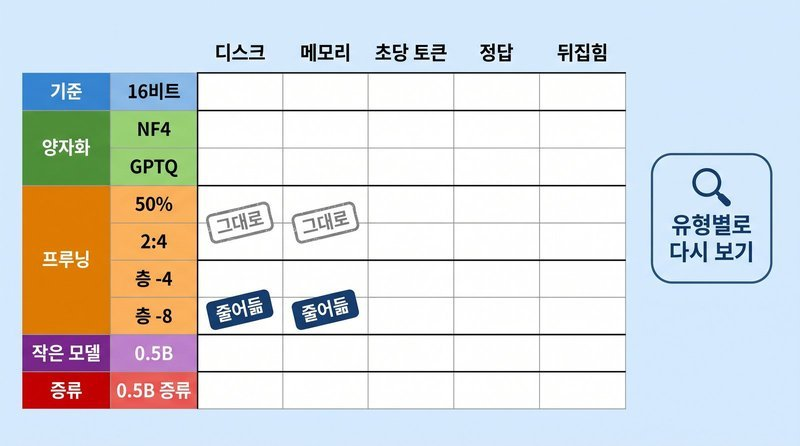

*같은 평가 코드로 양자화·프루닝·증류 모델을 비교하면, 무엇이 줄었고 어느 질문을 새로 틀렸는지 한 표에서 확인할 수 있습니다.*

**세 기법 비교표는 다음 노트에서 완성합니다.** 이 표의 양자화 행은 양자화 노트의 bitsandbytes 8비트·NF4뿐입니다. 다음 GPTQ·AWQ 실습 노트 Step 7에서 GPTQ·AWQ 행을 더하고 메모리 상한과 정답 하한을 먼저 걸어 가장 빠른 행을 고릅니다(이론 노트 6.1절). 그때 이 노트의 `d55_results.json`을 읽으므로 Step 8에서 팀 볼륨에 올려 둡니다.

### 실제 측정 결과로 선택하기

같은 GPU에서 다시 잰 메모리·속도·정답 수를 나란히 봅니다. 학생 모델과 교사 모델처럼 크기가 다른 비교는 양자화 기법 하나의 효과로 단정하지 않습니다. 막대가 낮다는 이유만으로 선택하지 않고 앞에서 확인한 바뀐 질문과 함께 설명합니다.

/tmp/ipykernel_2383/3450062981.py:14: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  fig.tight_layout();fig.savefig(WORK/"comparison.png",dpi=85);plt.show()
/tmp/ipykernel_2383/3450062981.py:14: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  fig.tight_layout();fig.savefig(WORK/"comparison.png",dpi=85);plt.show()
/tmp/ipykernel_2383/3450062981.py:14: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  fig.tight_layout();fig.savefig(WORK/"comparison.png",dpi=85);plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

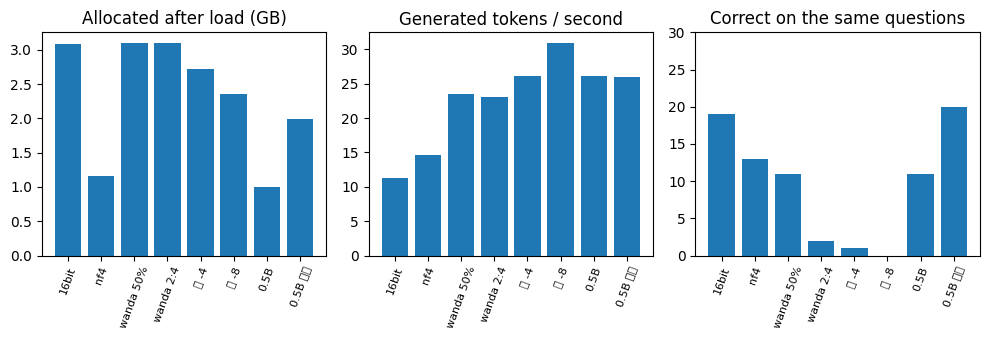

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
valid=[(name,row) for name,row in results.items() if isinstance(row,dict) and "correct" in row]
if valid:
    names=[name for name,row in valid]
    fig,axes=plt.subplots(1,3,figsize=(10,3.5))
    for ax,key,label in [(axes[0],"weights_gb","Allocated after load (GB)"),(axes[1],"tps","Generated tokens / second")]:
        ax.bar(range(len(valid)),[row.get(key,np.nan) for name,row in valid])
        ax.set(xticks=range(len(valid)),xticklabels=names,title=label)
        ax.tick_params(axis="x",rotation=70,labelsize=8)
    axes[2].bar(range(len(valid)),[sum(row["correct"].values()) for name,row in valid])
    axes[2].set(xticks=range(len(valid)),xticklabels=names,title="Correct on the same questions",ylim=(0,len(QUESTIONS)))
    axes[2].tick_params(axis="x",rotation=70,labelsize=8)
    fig.tight_layout();fig.savefig(WORK/"comparison.png",dpi=85);plt.show()

## Step 7. 선택 심화 트랙

두 트랙 중 **하나 이상을 골라** 수행하고 공유합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 트랙 | 주제 | 성격 | 난이도 |
|---|---|---|---|
| 1 | 층 제거 모델의 회복 학습 | 확장 | 상 |
| 2 | 프루닝 비율과 품질의 곡선 | 측정 | 하 |

</div>

SparseGPT 2:4, on-policy 증류, 제거할 층의 선택 기준은 마무리 과제 뒤의 부록 실습 A\~C에 있습니다.

#### 트랙 1. 층 제거 모델의 회복 학습

Step 5의 층 -8 모델에 Step 6의 교사 모델 답으로 LoRA를 붙여 회복 학습을 하고 같은 하네스로 다시 측정합니다.

In [ ]:
n_heal = max(DROP_LIST)
HEAL_SRC = WORK / f"1.5b-drop{n_heal}"
HEAL_DIR = WORK / f"1.5b-drop{n_heal}-healed"
rows = load_rows(DISTILL_FILE)
if not HEAL_SRC.exists() or not rows:
    print(f"{HEAL_SRC.name} 폴더나 증류 데이터가 없습니다. Step 5와 Step 6을 먼저 실행하세요")
elif distill_sft(HEAL_SRC, rows, HEAL_DIR, f"층 -{n_heal} 회복 학습 (교사 모델의 답으로 SFT, LoRA 합침)") is not None:
    measure_file(f"층 -{n_heal} 되살림", HEAL_DIR, "16bit", ref_repo=MODEL_ID, branch="프루닝")

Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

학습 111개, 검증 12개, max_length = 192

Tokenizing train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/111 [00:00<?, ? examples/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.51 -> 1.01 GB

Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.35 -> 1.01 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[층 -8 되살림] 정답 11/30 | 층 20 | 0 비율 0.0 | 초당 30.9 토큰 | 디스크 2.34 GB

In [ ]:
# 실습 : 16비트가 맞히고 층 -8이 틀린 질문 가운데 회복 학습한 모델이 다시 맞힌 질문의 id 목록을 만드세요
base_c = results.get("16bit", {}).get("correct")
cut_c = results.get(f"층 -{n_heal}", {}).get("correct")
heal_c = results.get(f"층 -{n_heal} 되살림", {}).get("correct")

if None in (base_c, cut_c, heal_c):
    print("16bit, 층 -8, 층 -8 되살림 행이 모두 있어야 합니다. Step 2, Step 5, 위 셀을 먼저 실행하세요")
else:
    ### START CODE HERE ### (잃었다가 되찾은 질문의 id 목록 1줄)
    # 1) base_c, cut_c, heal_c는 {질문 id: True/False}입니다. base_c가 맞히고 cut_c가 틀렸는데 heal_c가 맞힌 id만 모읍니다
    recovered = [k for k in base_c if base_c[k] and not cut_c[k] and heal_c[k]]
    ### END CODE HERE ###
    if recovered is None:
        print("recovered가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
    else:
        lost = [k for k in base_c if base_c[k] and not cut_c[k]]
        print(f"층을 제거하며 잃은 질문 {len(lost)}개 중 되찾은 질문 {len(recovered)}개 : {recovered}")
        print("유형 :", dict(Counter(q["type"] for q in QUESTIONS if q["id"] in recovered)))

층을 제거하며 잃은 질문 19개 중 되찾은 질문 10개 : ['A6', 'A7', 'A8', 'C1', 'C5', 'D1', 'D2', 'D4', 'D5', 'D6']
유형 : {'지문': 3, '분류': 2, '형식': 5}

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
recovered = [k for k in base_c if base_c[k] and not cut_c[k] and heal_c[k]]
```

증류 데이터는 벤치마크 하네스의 네 유형과 같은 형식이라 형식 질문과 분류 질문은 잘 돌아올 수 있습니다. 계산처럼 여러 단계가 필요한 질문이 돌아오지 않았다면 공개된 보고와 같은 모양입니다(이론 노트 4.3절).

</details>

#### 트랙 2. 프루닝 비율과 품질의 곡선

Step 4는 50%만 희소화했습니다. 비율을 20%에서 70%까지 바꿔 가며 Wanda로 프루닝하고 싼 측정으로 곡선을 그립니다.

In [ ]:
RATIOS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
curve = []
h = load_model(MODEL_ID, "16bit")
if "error" in h:
    print("로드 실패 :", h["error"])
else:
    base_ppl, base_preds, _ = perplexity_top1(h, TEXT_KO)
    norms = collect_input_norms(h, CALIB_TEXTS)
    backup = {n: m.weight.detach().to("cpu", copy=True) for n, m in decoder_linears(h["model"])}
    for ratio in RATIOS:
        with torch.no_grad():
            for n, m in decoder_linears(h["model"]):
                m.weight.copy_(backup[n].to(m.weight.device))        # 원래 가중치로 되돌립니다
        prune_wanda(h, norms, ratio)
        ppl, preds, _ = perplexity_top1(h, TEXT_KO)
        curve.append({"비율": ratio, "PPL비": round(ppl / base_ppl, 3), "1순위": round(top1_agreement(base_preds, preds), 3)})
        print(curve[-1])
    del backup
    unload(h)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

{'비율': 0.2, 'PPL비': 1.02, '1순위': 0.934}
{'비율': 0.3, 'PPL비': 1.063, '1순위': 0.872}
{'비율': 0.4, 'PPL비': 1.173, '1순위': 0.791}
{'비율': 0.5, 'PPL비': 1.847, '1순위': 0.624}
{'비율': 0.6, 'PPL비': 6.92, '1순위': 0.379}
{'비율': 0.7, 'PPL비': 1176.205, '1순위': 0.018}
  [언로드] GPU 메모리 4.10 -> 1.04 GB

In [ ]:
# 실습 : PPL비가 처음으로 1.1을 넘는 비율을 찾으세요. 끝까지 넘지 않으면 "넘지 않음"입니다
### START CODE HERE ### (PPL비가 처음 1.1을 넘는 비율 찾기 1줄)
# 1) curve는 {"비율", "PPL비", "1순위"} dict의 목록입니다. 앞에서부터 PPL비가 1.1을 넘는 첫 비율을, 없으면 "넘지 않음"을 넣습니다
knee = next((c["비율"] for c in curve if c["PPL비"] > 1.1), "넘지 않음")
### END CODE HERE ###

if knee is None:
    print("knee가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    print("PPL비가 1.1을 처음 넘는 비율 :", knee)

PPL비가 1.1을 처음 넘는 비율 : 0.4

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
knee = next((c["비율"] for c in curve if c["PPL비"] > 1.1), "넘지 않음")
```

1.1은 이 트랙에서 정한 표시일 뿐 품질 기준이 아닙니다.

**곡선이 완만한 구간도 안전하다는 뜻은 아닙니다.** 고른 비율은 하네스의 질문 30개로 다시 확인합니다.

</details>

## Step 8. RunPod 준비

오늘은 다음 두 날(GPTQ·AWQ, vLLM 기초) 실습에 쓸 팀 네트워크 볼륨을 만들고 **볼륨을 만든 데이터센터에서 가장 싼 GPU Pod**로 모델 파일을 미리 받아 둡니다. 다음 두 날은 코랩 대신 팀마다 RunPod Pod 하나(4인 1팀, 2팀)로 실습하며 32B 4비트 파일만 19.3GB라서 다음 날 48GB급 GPU를 켠 채 받으면 다운로드하는 동안에도 비싼 GPU 요금이 나갑니다.

**네트워크 볼륨에 대해 알아 둘 것** (RunPod 문서 확인 2026-11-02)

- 네트워크 볼륨은 Pod를 만들 때만 붙일 수 있습니다. 나중에 붙이거나 떼려면 Pod를 지우고 다시 만듭니다
- 볼륨은 보통 `/workspace`에 마운트됩니다
- Secure Cloud에서만 쓰고 볼륨을 만든 데이터센터의 GPU만 고를 수 있습니다. 그래서 데이터센터는 다음 날 쓸 48GB급 GPU(A40 또는 RTX A6000, 재고가 없으면 L40S)를 고를 수 있는 곳으로 정합니다
- Pod를 종료(terminate)해도 볼륨의 데이터는 남습니다. 컨테이너 디스크는 Pod를 멈추면 지워지므로 모델 파일, 캐시, 결과는 모두 `/workspace` 아래에 둡니다(`HF_HOME=/workspace/hf`, 오늘 결과는 `/workspace/results/d55/`)
- 요금은 RunPod 요금표에서 확인합니다. 이 노트에는 금액을 적지 않습니다

<div style="font-size: 18px; line-height: 1.6;">

| 받을 모델 | 크기 | 쓰는 곳 |
|---|---|---|
| `Qwen/Qwen2.5-32B-Instruct-AWQ` | 19.3GB (4비트 AWQ, 64층) | 다음 노트의 32B 측정, vLLM 기초 노트의 서빙 |
| `Qwen/Qwen2.5-7B-Instruct` | 받은 뒤 크기를 적습니다 | 다음 노트의 7B 직접 양자화, vLLM 기초 노트의 16비트 비교 |

</div>

볼륨 100GB는 두 파일과 다음 노트에서 만들 7B 4비트 파일, 결과 파일을 담고 남습니다. 같은 볼륨을 GPU 클러스터와 분산 학습 날까지 씁니다.

볼륨은 **100GB로 시작**하고 D61에 150GB로 확장할 계획입니다.  
계정과 결제는 강사가 관리합니다. 팀은 할당받은 볼륨과 접속 주소를 확인하고 콘솔 권한이 없는 경우 기동·종료를 강사에게 요청해 함께 확인합니다. 다음 날 사용할 A40 또는 RTX A6000의 재고와 같은 데이터센터인지 먼저 확인합니다.

**역할표** (이름을 적습니다. 네 명이 한 단계씩 직접 실행하고 나머지는 화면을 함께 봅니다)

<div style="font-size: 18px; line-height: 1.6;">

| 역할 | 맡은 일 | 이름 |
|---|---|---|
| A | 팀 네트워크 볼륨 만들기 (100GB, Secure Cloud, 데이터센터 고르기) | |
| B | 그 볼륨을 붙여 그 데이터센터에서 가장 싼 GPU Pod 기동, `/workspace` 확인, 코랩 파일 업로드 | |
| C | `HF_HOME` 설정과 32B AWQ 다운로드 | |
| D | 7B 원본 다운로드, 크기 확인, 종료 점검표와 Pod 종료 | |

</div>

**순서**

1. **A** : RunPod 콘솔에서 네트워크 볼륨을 만듭니다. 크기 100GB, 데이터센터는 위의 조건으로 고릅니다
2. **B** : Pod를 만들면서 그 볼륨을 고르고 그 데이터센터에서 가장 싼 GPU를 골라 기동합니다. Pod의 터미널에서 `df -h /workspace`로 볼륨이 붙었는지 봅니다
3. **B** : Pod의 Jupyter 화면에서 코랩에서 만든 파일을 `/workspace` 아래로 업로드합니다. `d55_results.json`은 `/workspace/results/d55/`에, `bench_harness.py`는 `/workspace/`에, D53의 `serving_project`는 참고용 선택 파일입니다. D57에서는 독립 실행에 필요한 API 파일을 다시 제공합니다
4. **C, D** : 아래 셀의 명령을 **Pod의 터미널에서** 한 줄씩 실행합니다(C는 32B, D는 7B와 크기 확인). 코랩에서 실행하면 `/workspace`가 없어 바로 끝납니다  
5. **D** : 종료 점검표를 채운 뒤 Pod를 종료합니다

In [ ]:
%%bash
# Step 8 : 팀 볼륨을 붙인 RunPod Pod의 터미널에서 실행합니다(코랩에서는 바로 끝납니다)
if [ ! -d /workspace ]; then echo "/workspace 가 없습니다. RunPod Pod에서 실행합니다"; exit 0; fi
export HF_HOME=/workspace/hf                     # 모델 캐시를 볼륨에 둡니다
mkdir -p "$HF_HOME" /workspace/results/d55      # 오늘 결과 파일을 올릴 곳
pip install -q -U huggingface_hub               # hf 명령은 huggingface_hub 에 들어 있습니다

hf download Qwen/Qwen2.5-32B-Instruct-AWQ        # 역할 C. 19.3GB
hf download Qwen/Qwen2.5-7B-Instruct             # 역할 D

# 크기 확인(역할 D). du 는 1024 단위로 세므로 19.3GB 인 32B AWQ 가 18G 안팎으로 출력됩니다
du -sh $HF_HOME/hub/models--Qwen--Qwen2.5-32B-Instruct-AWQ $HF_HOME/hub/models--Qwen--Qwen2.5-7B-Instruct
df -h /workspace

/workspace 가 없습니다. RunPod Pod에서 실행합니다

폴더 크기만으로 다운로드 완료나 중단을 확정하지 않습니다. 같은 저장소·리비전의 파일 목록과 실제 파일 존재를 함께 확인합니다. 같은 `hf download` 명령을 다시 실행하면 이미 받은 파일은 캐시에서 건너뜁니다.

**종료 점검표** (D가 확인하고 팀원 모두가 봅니다)

- [ ] 두 모델 폴더의 크기를 역할표 아래에 적었다
- [ ] Pod를 종료(terminate)했다. 볼륨의 데이터는 남는다
- [ ] 콘솔에서 네트워크 볼륨이 남아 있는지 확인했다. 볼륨은 지우지 않는다
- [ ] 오늘 쓴 요금을 RunPod 콘솔에서 확인했다(금액은 노트에 적지 않는다)
- [ ] `/workspace/results/d55/d55_results.json`과 `/workspace/bench_harness.py`를 확인했습니다. D57 API 준비 코드는 해당 노트가 제공합니다.

다음 노트의 Step 0은 같은 데이터센터에서 이 볼륨을 붙여 48GB급 GPU Pod를 기동하는 일로 시작합니다.

## Step 9. 공유와 정리

**줄였다는 말은 무엇이 줄었는지 수치로 출력할 때까지 믿지 않습니다.** 팀 안에서 결과를 모으고 두 팀이 같은 형식으로 공유합니다.

**1. 오늘의 표** : Step 6의 표에서 여러분 GPU의 디스크, 메모리, 초당 토큰, 정답, flip

**2. 줄어든 것과 그대로인 것** : 희소화한 행과 층을 제거한 행에서 디스크, 메모리, 속도 중 무엇이 실제로 줄었는지

**3. 정오답이 달라진 문항** : 층을 제거한 행과 증류한 학생 모델이 틀리게 답한 질문의 유형. 분류와 계산·형식 가운데 어디서 먼저 잃었는지

**4. 선택한 트랙의 결과** : 고른 트랙에서 얻은 판단 하나와 판단의 근거가 된 수치

**5. RunPod 준비** : 역할표, 두 모델 폴더의 크기, Pod를 종료했는지. 두 팀의 표를 나란히 놓고 크기가 같은지 봅니다

### 혼자 설명하기

가중치에서 0의 비율은 늘었지만 생성 속도는 그대로인 모델과, 더 작은 학생 모델 중 어느 것을 사용할지 설명합니다. 파일 크기·메모리·속도 중 실제로 줄어든 항목과 새로 틀린 질문 유형을 근거로 듭니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 바꾸고 실행한 내용 | 사용한 입력과 설정, 실제 출력 |
| [목표 2] 비교한 결과와 판단 | 그대로 둔 설정과 바꾼 설정, 직접 측정한 결과인지 여부 |
| [목표 3] 다시 실행할 때 필요한 기록 | 저장한 파일과 선택에 사용한 측정값 |

D56에서는 보정 입력을 사용해 GPTQ·AWQ 모델 파일을 만듭니다. D57에서는 그 파일을 vLLM 서버로 실행합니다.

## 마무리 과제. 경량화 판단서

여러분이 가정한 사내 서비스에 배포할 모델을 오늘의 표에서 고르고 판단서 초안을 씁니다. 다음 GPTQ·AWQ 노트에서 GPTQ·AWQ 행을 더해 판단서를 마무리합니다.

**1단계. 조건**

1. 사내 GPU의 이름과 compute capability, 남는 메모리, 동시 사용자 수를 적습니다  
2. 허용할 수 있는 정답 하한과 꼭 지켜야 할 질문 유형(예 : JSON 형식)을 서비스 담당자와 정합니다

**2단계. 후보**

3. 이론 노트 6.1절의 순서대로 이미 나와 있는 작은 모델, 양자화, 층 제거와 증류를 차례로 후보에 넣습니다  
4. 후보마다 만드는 데 드는 GPU 시간과 데이터(보정 글, 교사 모델의 답)를 적습니다. 증류라면 교사 모델의 라이선스를 함께 적습니다

**3단계. 측정**

5. 여러분 업무의 질문을 유형별로 40개 이상 만듭니다. 증류 데이터와 내용이 겹치지 않는지 Step 6의 방식으로 검사합니다  
6. 원본과 후보 셋 이상을 Step 6의 표로 측정합니다  
7. 정오답이 달라진 문항을 유형별로 읽고 무엇이 망가졌는지 한 줄씩 적습니다

**4단계. 선택과 기록**

8. 이론 노트 6.1절처럼 조건(메모리 상한, 정답 하한)을 먼저 걸고 남은 후보에서 속도로 고릅니다  
9. 고른 모델의 카드(모델 카드나 증류 카드)를 남기고 다시 측정할 날을 적습니다

**평가 기준**

고른 기법이 아니라 **근거와 재현**으로 평가합니다.

평가 질문과 증류 데이터가 겹치지 않았다는 확인이 빠진 판단서는 통과하지 않습니다.

## 부록 실습 A. llm-compressor로 만드는 SparseGPT 2:4

본 실습을 마친 뒤 시간이 남거나 더 깊이 보고 싶을 때 하는 실습입니다. 본 실습 Step 6까지 실행한 상태에서 시작합니다.

llm-compressor 0.14.0은 transformers를 5.17.0으로 다운그레이드하고 torch를 2.10\~2.14.0 범위로 맞춥니다. 그래서 이 실습은 **오늘의 마지막에 하고** 만들기는 별도 파이썬 프로세스에서 실행합니다. 끝나면 런타임을 새로 받습니다. GPTQ·AWQ 실습 노트 부록 실습 F에서 4비트 파일을 만들 때도 같은 도구를 씁니다.

 **로컬 작업** : 사내 서버에서는 llm-compressor를 따로 만든 가상환경에 설치하고 그 파이썬의 경로를 `D55_PYTHON`에 적습니다.

In [ ]:
!pip install -q "llmcompressor>=0.14,<0.15" "compressed-tensors>=0.19,<0.20"

In [ ]:
import subprocess, sys

SGPT_DIR = WORK / "1.5b-sparsegpt-2of4"
CALIB_FILE = WORK / "calib_ko.json"
CALIB_FILE.write_text(json.dumps({"texts": CALIB_TEXTS}, ensure_ascii=False), encoding="utf-8")
SGPT_SCRIPT = WORK / "sparsegpt_track.py"
SGPT_SCRIPT.write_text(r'''
import json, sys, time
from importlib.metadata import version
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import Dataset
from llmcompressor import oneshot
from llmcompressor.modifiers.pruning import SparseGPTModifier

base, out, calib_file, structure = sys.argv[1], sys.argv[2], sys.argv[3], sys.argv[4]
print("transformers", version("transformers"), "/ llmcompressor", version("llmcompressor"),
      "/ compressed-tensors", version("compressed-tensors"))
tok = AutoTokenizer.from_pretrained(base)
model = AutoModelForCausalLM.from_pretrained(base, dtype=torch.float16)
texts = json.load(open(calib_file, encoding="utf-8"))["texts"]
ds = Dataset.from_dict({"text": texts}).map(
    lambda s: tok(s["text"], truncation=True, max_length=256, add_special_tokens=False), remove_columns=["text"])
t0 = time.time()
oneshot(model=model, dataset=ds,
        recipe=SparseGPTModifier(sparsity=0.5, mask_structure=structure, targets=["Linear"], ignore=["lm_head"]),
        max_seq_length=256, num_calibration_samples=len(texts))
model.save_pretrained(out, save_compressed=True)
tok.save_pretrained(out)
cfg = json.load(open(f"{out}/config.json", encoding="utf-8"))
print(json.dumps({"minutes": round((time.time() - t0) / 60, 1),
                  "quantization_config": cfg.get("quantization_config")}, ensure_ascii=False))
''', encoding="utf-8")

# 실습 : SparseGPTModifier의 mask_structure에 넘길 2:4 패턴의 문자열을 적으세요(llm-compressor 문서의 예와 같은 모양)
### START CODE HERE ### (mask_structure에 넘길 2:4 패턴 문자열 1줄)
# 1) 원소 4개마다 2개를 제거하는 2:4 패턴을 문자열로 적습니다
STRUCTURE = "2:4"
### END CODE HERE ###

PYTHON = os.environ.get("D55_PYTHON", sys.executable)
if STRUCTURE is None:
    print("STRUCTURE가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    proc = subprocess.run([PYTHON, str(SGPT_SCRIPT), str(MODEL_ID), str(SGPT_DIR), str(CALIB_FILE), STRUCTURE],
                          capture_output=True, text=True)
    # llm-compressor의 진행 기록(" | "가 든 줄)은 빼고 출력합니다
    print("\n".join(x for x in proc.stdout.splitlines() if " | " not in x)[-3000:])
    if proc.returncode != 0:
        print("실패 :", proc.stderr[-1500:])
    elif SGPT_DIR.exists():
        measure_file("sparsegpt 2:4", SGPT_DIR, "16bit", ref_repo=MODEL_ID, branch="프루닝")

transformers 5.17.0 / llmcompressor 0.14.0.1 / compressed-tensors 0.19.0
{"minutes": 16.2, "quantization_config": null}

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 4.13 -> 1.04 GB
[sparsegpt 2:4] 정답 0/30 | 층 28 | 0 비율 0.5 | 초당 21.5 토큰 | 디스크 3.09 GB

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
STRUCTURE = "2:4"
```

출력의 `quantization_config`를 봅니다. 압축해서 저장하라고(`save_compressed=True`) 했는데도 **`null`이 출력되고 파일 크기는 원본과 같습니다.** compressed-tensors 0.15부터 2:4 저장 형식이 빠져서 0을 그대로 담은 보통 파일이 나옵니다(이론 노트 6장 심화 ‘2026년 10월의 도구 사정’).

</details>

## 부록 실습 B. on-policy 증류

이 트랙에서는 **학생 모델이 직접 답을 쓰고 교사 모델이 학생 모델의 답 토큰마다 점수를 매기게** 합니다(이론 노트 5장 심화 ‘학생 모델이 쓴 답을 고치는 on-policy 증류’).

교사 모델과 학생 모델을 함께 로드해야 해서 GPU 메모리를 가장 많이 씁니다.

In [ ]:
from trl import DistillationConfig, DistillationTrainer

OPD_STEPS = int(os.environ.get("D55_OPD_STEPS", "40"))
OPD_DIR = WORK / "0.5b-onpolicy"

# 실습 : 이론 노트 5장 심화 ‘학생 모델이 쓴 답을 고치는 on-policy 증류’의 역방향 KL에 해당하는 beta 값을 적으세요(DistillationConfig 설명 : 0은 정방향 KL, 1은 역방향 KL)
### START CODE HERE ### (역방향 KL에 해당하는 beta 값 1줄)
# 1) 정방향 KL(0)과 역방향 KL(1) 가운데 역방향 쪽 끝 값을 실수로 적습니다
BETA = 1.0
### END CODE HERE ###

rows = load_rows(DISTILL_FILE)
if BETA is None:
    print("BETA가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
elif not rows:
    print("증류 데이터가 없습니다. Step 6을 먼저 실행하세요")
else:
    hs, ht = load_model(STUDENT_ID, "16bit"), load_model(MODEL_ID, "16bit")
    if "error" in hs or "error" in ht:
        print("로드 실패 :", hs.get("error"), ht.get("error"))
    else:
        hs["tok"].padding_side = "left"                     # 학생 모델이 답을 이어 쓸 위치를 시퀀스 끝에 둡니다
        prompts = Dataset.from_list([{"prompt": r["messages"][:2]} for r in rows])   # 시스템과 질문만 넘깁니다
        cfg = DistillationConfig(
            output_dir=str(WORK / "opd_out"), max_steps=OPD_STEPS,
            per_device_train_batch_size=4, gradient_accumulation_steps=2,
            learning_rate=1e-4,                             # LoRA라서 이 트레이너의 기본값(1e-6)보다 크게
            max_completion_length=64, beta=BETA, logging_steps=5, save_strategy="no", report_to="none",
            bf16=HAS_GPU and NATIVE_BF16, fp16=HAS_GPU and not NATIVE_BF16,   # 이 트레이너는 bf16이 기본이라 꼭 적습니다
            seed=42,
        )
        trainer = DistillationTrainer(
            model=hs["model"], teacher_model=ht["model"], args=cfg, train_dataset=prompts,
            processing_class=hs["tok"],
            peft_config=LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear",
                                   task_type="CAUSAL_LM"))
        if HAS_GPU:
            torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        trainer.train()
        print(f"on-policy 증류 {OPD_STEPS}스텝 {(time.time() - t0) / 60:.1f}분 | GPU 최고점 {fmt(vram_gb(peak=True), '.2f')} GB")
        print("손실 :", [round(x["loss"], 4) for x in trainer.state.log_history if "loss" in x])
        merged = trainer.model.merge_and_unload()
        merged.save_pretrained(OPD_DIR)
        AutoTokenizer.from_pretrained(STUDENT_ID).save_pretrained(OPD_DIR)
        del trainer, merged
        unload(ht)
        unload(hs)
        measure_file("0.5B 정책 위", OPD_DIR, "16bit", ref_repo=STUDENT_ID, branch="증류")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

<IPython.core.display.HTML object>

on-policy 증류 40스텝 3.0분 | GPU 최고점 5.38 GB
손실 : [0.5613, 0.2679, 0.1043, 0.1395, 0.0849, 0.0961, 0.1309, 0.0489]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [언로드] GPU 메모리 5.22 -> 2.03 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
  [언로드] GPU 메모리 2.03 -> 1.04 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  [언로드] GPU 메모리 2.03 -> 1.04 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[0.5B 정책 위] 정답 16/30 | 층 24 | 0 비율 0.0 | 초당 26.0 토큰 | 디스크 0.99 GB

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
BETA = 1.0
```

Step 6의 표(`overview()`)에서 `0.5B 증류`(시퀀스 증류)와 `0.5B 정책 위`(on-policy 증류) 행을 비교합니다. 스텝 수가 적어서 on-policy 행이 더 낫다는 보장은 없습니다. **걸린 시간과 GPU 최고점을 함께 적습니다.** 같은 시간을 썼을 때 어느 쪽이 더 얻었는지가 고르는 근거입니다.

</details>

## 부록 실습 C. 제거할 층의 선택 기준

Step 5는 변화가 작은 층을 골랐습니다. 이 기준이 나은지 **끝에서부터 고르기**와 **무작위로 고르기**와 비교합니다.

세 기준을 다 하네스로 측정하면 30분이 넘으므로 먼저 싼 측정(퍼플렉서티 비율과 1순위 일치율)으로 좁히고 가장 나은 하나만 하네스로 확인합니다.

In [ ]:
# 실습 : 첫 층과 마지막 층을 빼고 끝에서부터 n개를 고르는 함수를 완성하세요
def pick_back(n_layers, n):
    ### START CODE HERE ### (마지막 층 바로 앞에서부터 n개의 층 번호 1줄)
    # 1) 마지막 층(n_layers - 1)은 빼고 그 앞의 n개를 작은 번호부터 적습니다. 층이 28개이고 n이 4면 [23, 24, 25, 26]입니다
    picked = list(range(n_layers - 1 - n, n_layers - 1))
    ### END CODE HERE ###
    return picked


def pick_random(n_layers, n, seed=0):
    return sorted(random.Random(seed).sample(range(1, n_layers - 1), n))


@torch.no_grad()
def cheap_check(drop):
    """층을 제거한 모델의 한국어 퍼플렉서티 비율과 1순위 일치율. 하네스의 함수로 측정합니다"""
    h = load_model(MODEL_ID, "16bit")
    drop_layers(h["model"], drop)
    ppl, preds, _ = perplexity_top1(h, TEXT_KO)
    unload(h)
    return ppl / BASE_PPL, top1_agreement(BASE_PREDS, preds)


n4 = min(DROP_LIST)
h = load_model(MODEL_ID, "16bit")
BASE_PPL, BASE_PREDS, _ = perplexity_top1(h, TEXT_KO)
n_layers = h["model"].config.num_hidden_layers
unload(h)
picks = {"변화가 작은 층": pick_layers_to_drop(CHANGE, n4) if CHANGE else None,
         "끝에서부터": pick_back(n_layers, n4), "무작위": pick_random(n_layers, n4)}
if any(v is None for v in picks.values()):
    print("pick_back이나 Step 5의 실습이 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    for name, drop in picks.items():
        ratio, agree = cheap_check(drop)
        print(f"{name:<10} 제거한 층 {drop} | PPL비 한 {ratio:.3f} | 1순위 한 {agree:.1%}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 4.13 -> 1.04 GB

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.75 -> 1.04 GB
변화가 작은 층   제거한 층 [12, 14, 15, 16] | PPL비 한 1.299 | 1순위 한 73.0%

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.75 -> 1.04 GB
끝에서부터      제거한 층 [23, 24, 25, 26] | PPL비 한 17.274 | 1순위 한 29.9%

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 3.75 -> 1.04 GB
무작위        제거한 층 [2, 13, 14, 25] | PPL비 한 3.089 | 1순위 한 52.5%

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
picked = list(range(n_layers - 1 - n, n_layers - 1))
```

퍼플렉서티 비율이 1에 가깝고 1순위 일치율이 높을수록 원본과 가깝습니다. 무작위로 고른 층은 대개 가장 나쁩니다.

</details>

## 부록 실습 D. 0을 담은 행렬과 2:4 희소 곱셈

본 실습 Step 3의 `mask_unstructured`와 `mask_2of4`를 씁니다. 먼저 2048 × 2048 행렬의 절반을 0으로 바꿔 메모리와 곱셈 시간이 그대로인지 보고(이론 노트 3.1절), compute capability 8.0 이상(L4 8.9, A100 8.0)이면 2:4 행렬을 희소 형식으로 바꿔 곱셈 시간을 비교합니다(이론 노트 3.3절). T4(7.5)에서는 두 번째 곱셈을 건너뜁니다.

절반을 0으로 바꾼 행렬이 실제로 작아지고 빨라지는지 봅니다.

In [ ]:
A = torch.randn(2048, 2048)
A_half = A * mask_unstructured(A.abs(), 0.5)
x = torch.randn(256, 2048)


def bench(m, repeat=20):
    """행렬 곱셈 한 번의 평균 시간(ms)"""
    for _ in range(3):
        x @ m.T
    t0 = time.perf_counter()
    for _ in range(repeat):
        x @ m.T
    return (time.perf_counter() - t0) / repeat * 1000


print(f"0 비율 {float((A_half == 0).float().mean()):.0%}")
print(f"메모리 : 원래 {A.nelement() * A.element_size() / 1e6:.1f} MB / 절반을 0으로 {A_half.nelement() * A_half.element_size() / 1e6:.1f} MB")
print(f"곱셈 : 원래 {bench(A):.2f} ms / 절반을 0으로 {bench(A_half):.2f} ms (CPU, 측정 변동이 있습니다)")

# 2:4 저장 형식의 어림 계산 (16비트 기준). 원소 4개 64비트 -> 남긴 값 2개 32비트 + 인덱스 2개 4비트
dense_bits, sparse_bits = 4 * 16, 2 * 16 + 2 * 2
print(f"2:4 형식으로 담으면 원래 크기의 {sparse_bits / dense_bits:.0%} (값 절반과 인덱스)")

0 비율 50%
메모리 : 원래 16.8 MB / 절반을 0으로 16.8 MB
곱셈 : 원래 18.40 ms / 절반을 0으로 19.47 ms (CPU, 측정 변동이 있습니다)
2:4 형식으로 담으면 원래 크기의 56% (값 절반과 인덱스)

In [ ]:
def first_line(e):
    text = str(e).strip()
    return f"{type(e).__name__}: {text.splitlines()[0][:200] if text else ''}"


# compute capability가 8.0 이상이면 2:4 행렬을 희소 형식으로 바꿔 곱셈 시간을 측정합니다. T4(7.5)에서는 이 곱셈을 건너뜁니다
if HAS_GPU and CAP >= (8, 0) and mask_2of4(torch.ones(1, 4)) is not None:
    from torch.sparse import to_sparse_semi_structured
    try:
        Wd = torch.randn(4096, 4096, dtype=torch.float16, device="cuda")
        Wd = Wd * mask_2of4(Wd.abs()).to(Wd.dtype)
        Ws = to_sparse_semi_structured(Wd)
        x16 = torch.randn(128, 4096, dtype=torch.float16, device="cuda")

        def gbench(w, repeat=50):
            for _ in range(5):
                F.linear(x16, w)
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            for _ in range(repeat):
                F.linear(x16, w)
            torch.cuda.synchronize()
            return (time.perf_counter() - t0) / repeat * 1000

        print(f"{torch.cuda.get_device_name(0)} : 보통 행렬 {gbench(Wd):.3f} ms / 2:4 희소 형식 {gbench(Ws):.3f} ms")
    except Exception as e:
        print("희소 형식으로 곱하지 못했습니다 :", first_line(e))
elif HAS_GPU and CAP < (8, 0):
    print(f"compute capability {CAP[0]}.{CAP[1]} : 8.0 미만이라 희소 텐서 코어가 없습니다.")
    print("2:4로 프루닝한 모델도 이 GPU에서는 0을 담은 보통 행렬로 계산합니다.")
else:
    print("GPU가 없거나 mask_2of4가 비어 있어 이 셀을 건너뜁니다")

compute capability 7.5 : 8.0 미만이라 희소 텐서 코어가 없습니다.
2:4로 프루닝한 모델도 이 GPU에서는 0을 담은 보통 행렬로 계산합니다.

## 부록 실습 E. 첫 토큰 시간과 디코드 속도 나눠 재기

하네스의 초당 토큰은 답을 쓰는 속도 하나입니다. 이 실습은 긴 규정 글을 넣었을 때의 **첫 토큰 시간**(프리필)과 그 뒤의 **디코드 속도**를 나눠 측정해 Step 6 표의 `첫 토큰 s` 열을 채웁니다. 층을 제거한 행은 프리필도 함께 빨라지는지 봅니다. 본 실습 Step 6까지 실행한 상태에서 시작하고 다음 GPTQ·AWQ 노트의 행과 첫 토큰 시간을 비교하려면 이 실습을 한 뒤 결과 파일을 올립니다.

In [ ]:
LONG_PROMPT = TEXT_KO + "\n\n질문 : 이 규정에서 휴가와 관련된 조항을 모두 찾아 조항마다 한 문장으로 설명하십시오."


@torch.no_grad()
def split_speed(h, prompt, n_new=64, repeat=3):
    """첫 토큰 시간과 디코드 속도를 나눠 측정합니다(중앙값)"""
    enc = chat_inputs(h, prompt)
    kw = {"do_sample": False, "pad_token_id": h["tok"].pad_token_id}
    h["model"].generate(**enc, max_new_tokens=8, **kw)        # 예열
    ttfts, totals = [], []
    for _ in range(repeat):
        for n, bucket in ((1, ttfts), (n_new, totals)):
            if HAS_GPU:
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            h["model"].generate(**enc, max_new_tokens=n, min_new_tokens=n, **kw)
            if HAS_GPU:
                torch.cuda.synchronize()
            bucket.append(time.perf_counter() - t0)
    ttft, total = sorted(ttfts)[repeat // 2], sorted(totals)[repeat // 2]
    return {"input_tokens": enc["input_ids"].shape[1], "ttft_s": round(ttft, 3),
            "decode_tps": round((n_new - 1) / max(total - ttft, 1e-6), 1)}


paths = {"16bit": MODEL_ID, **PRUNE_DIRS, **DROP_DIRS, "0.5B": STUDENT_ID, "0.5B 증류": STUDENT_DIR}
for name, path in paths.items():
    if "correct" not in results.get(name, {}):
        continue
    h = load_model(str(path), "16bit")
    if "error" in h:
        print(f"[{name}] 로드 실패 : {h['error']}")
        continue
    results[name].update(split_speed(h, LONG_PROMPT))
    unload(h)
    print(f"[{name}] 첫 토큰 {results[name]['ttft_s']} s | 디코드 {results[name]['decode_tps']} 토큰/초")
save_results()
display(overview())

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 4.13 -> 1.04 GB
[16bit] 첫 토큰 0.202 s | 디코드 23.8 토큰/초

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 4.13 -> 1.04 GB
[wanda 50%] 첫 토큰 0.197 s | 디코드 23.5 토큰/초

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [언로드] GPU 메모리 4.13 -> 1.04 GB
[wanda 2:4] 첫 토큰 0.199 s | 디코드 23.4 토큰/초

... (6 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  [언로드] GPU 메모리 2.03 -> 1.04 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[0.5B 증류] 첫 토큰 0.104 s | 디코드 25.3 토큰/초

/tmp/ipykernel_2383/1176878386.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.DataFrame(rows, dtype=object).set_index("이름").fillna("-")

                  갈래  잰 곳   층 0 비율  디스크 GB  올린 직후 GB 첫 토큰 s  초당 토큰  PPL비 한  \
이름                                                                           
16bit             기준  D55  28  0.0    3.09      3.09  0.202   11.3       -   
nf4              양자화  D55  28    -    3.09      1.16      -   14.6   1.104   
wanda 50%        프루닝  D55  28  0.5    3.09      3.10  0.197   23.5   1.847   
wanda 2:4        프루닝  D55  28  0.5    3.09      3.10  0.199   23.0   7.495   
층 -4             프루닝  D55  24  0.0    2.71      2.73  0.174   26.1   1.299   
층 -8             프루닝  D55  20  0.0    2.34      2.35  0.143   30.9   2.877   
층 -8 되살림         프루닝  D55  20  0.0    2.34      3.35      -   30.9   2.691   
sparsegpt 2:4    프루닝  D55  28  0.5    3.09      4.13      -   21.5  139.76   
0.5B           작은 모델  D55  24  0.0    0.99      1.00  0.102   26.1   1.504   
0.5B 증류           증류  D55  24  0.0    0.99      2.00  0.104   26.0    1.58   
0.5B 정책 위         증류  D55  24  0.0    0.99      2.03      -   26